In [1]:
# Chạy cell này ĐẦU TIÊN và đợi nó chạy xong
!pip install -q "monai[all]"
!pip install -q nibabel tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.2/47.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.5/266.5 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.9/80.9 MB 23.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 MB 28.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.0/28.0 MB 54.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 35.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 65.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 88.0 MB/s eta

In [2]:
!pip install medpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 4.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for medpy: filename=MedPy-0.5.2-py3-none-any.whl size=224710 sha256=f47b416c7c21d29caf8a0aed68177cd76ac620c1651ba6d13c2129c15d934f4c
  Stored in directory: /root/.cache/pip/wheels/89/5a/f8/b3def53b9c2133d2f8698ea2173bb5df63bd8e761ce8e9aec9
Successfully built medpy


# **Config**

In [3]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from medpy.metric.binary import dc, jc, hd95
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference

# ---------------- 0. CONFIGURATION ----------------
ROOT_DIR = Path("/kaggle/input/m-and-ms-dataset/MnM2/dataset")
SAVE_DIR = Path("./segresnet3d_final_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 64)
NUM_CLASSES = 4
BATCH_SIZE = 2
EPOCHS = 100
LR = 1e-4
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, NUM_CLASSES).permute(0,4,1,2,3).float()
        dims = (0,2,3,4)
        inter = torch.sum(pred[:,1:] * target_oh[:,1:], dims)
        union = torch.sum(pred[:,1:] + target_oh[:,1:], dims)
        return 1 - ((2*inter + self.smooth) / (union + self.smooth)).mean()

# ---------------- 2. DATASET (RESIZE ONLY – NO CROP) ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt  = nib.load(gt_p).get_fdata().astype(np.int64)

        zoom = (
            TARGET_SIZE[0] / img.shape[0],
            TARGET_SIZE[1] / img.shape[1],
            TARGET_SIZE[2] / img.shape[2]
        )
        img = ndi.zoom(img, zoom, order=1)
        gt  = ndi.zoom(gt,  zoom, order=0)

        if self.augment:
            if random.random() > 0.5:
                ax = random.randint(0,2)
                img = np.flip(img, ax).copy()
                gt  = np.flip(gt, ax).copy()

        img = (img - img.mean()) / (img.std() + 1e-6)

        return {
            "image": torch.from_numpy(img[None]).float(),
            "label": torch.from_numpy(gt).long()
        }

# ---------------- 3. METRICS ----------------
def get_metrics(p, g):
    res = {}
    for cl, name in zip([1,2,3], ['LV','RV','MYO']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0:
            res[name] = (0.0, 0.0, 50.0)
            continue
        res[name] = (
            dc(pc, gc),
            jc(pc, gc),
            hd95(pc, gc) if pc.sum()>0 else 50.0
        )
    return res

# ---------------- 4. PREPARE DATA ----------------
items = []
for p in sorted(ROOT_DIR.iterdir()):
    if not p.is_dir(): continue
    for s in ["ED","ES"]:
        img = p/f"{p.name}_SA_{s}.nii"
        gt  = p/f"{p.name}_SA_{s}_gt.nii"
        if img.exists() and gt.exists():
            items.append((str(img), str(gt)))

tr_items, tmp = train_test_split(items, test_size=0.3, random_state=SEED)
va_items, te_items = train_test_split(tmp, test_size=0.5, random_state=SEED)

loaders = {
    "train": DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    "val":   DataLoader(VolumeDataset(va_items), 1)
}

# ---------------- 5. MODEL ----------------
model = SegResNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    init_filters=32,
    dropout_prob=0.2
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, "max", patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler("cuda")

best_dice = 0.0

# ---------------- 6. CSV LOG ----------------
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, "w", newline="") as f:
    csv.writer(f).writerow([
        "epoch","tr_loss","va_loss","tr_dice",
        "va_dice","va_iou","va_hd95",
        "lv_d","rv_d","myo_d","time"
    ])

print(f"Training SegResNet3D | Train {len(tr_items)} | Val {len(va_items)} | Test {len(te_items)}")
print("-"*170)

2026-01-04 17:32:42.987080: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767547963.197434      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767547963.269225      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1767547963.804467      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767547963.804514      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767547963.804517      55 computation_placer.cc:177] computation placer alr

Training SegResNet3D | Train 504 | Val 108 | Test 108
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


# **Trainning**

In [ ]:


# ---------------- 7. TRAINING LOOP ----------------
for ep in range(1, EPOCHS+1):
    t0 = time.time()
    model.train()
    tr_l, tr_d = [], []

    for b in tqdm(loaders["train"], desc=f"Epoch {ep:02d}", leave=False):
        img = b["image"].to(DEVICE)
        lab = b["label"].to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            out = model(img)
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_l.append(loss.item())
        tr_d.append(dc((out.argmax(1)>0).cpu().numpy(), (lab>0).cpu().numpy()))

    # ---------------- VALIDATION (FULL IMAGE) ----------------
    model.eval()
    va_l, acc = [], {"LV":[], "RV":[], "MYO":[]}

    with torch.no_grad():
        for b in loaders["val"]:
            img = b["image"].to(DEVICE)
            lab = b["label"].to(DEVICE)

            out = sliding_window_inference(
                img,
                roi_size=TARGET_SIZE,
                sw_batch_size=1,
                predictor=model,
                overlap=0.5
            )

            loss = ce_criterion(out, lab) + dice_criterion(out, lab)
            va_l.append(loss.item())

            p = out.argmax(1).cpu().numpy()[0]
            g = lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for k in acc: acc[k].append(m[k])

    tr_loss = np.mean(tr_l)
    va_loss = np.mean(va_l)
    tr_dice = np.mean(tr_d)

    stats = {k: np.mean(acc[k],0) for k in acc}
    va_dice = np.mean([stats[k][0] for k in stats])
    va_iou  = np.mean([stats[k][1] for k in stats])
    va_hd95 = np.mean([stats[k][2] for k in stats])

    scheduler.step(va_dice)
    t_total = time.time() - t0

    print(
        f"Ep {ep:02d} | {t_total:5.1f}s | "
        f"Tr.Loss {tr_loss:.4f} | Va.Loss {va_loss:.4f} | "
        f"Tr.Dice {tr_dice:.4f} | Va.Dice {va_dice:.4f} | "
        f"IoU {va_iou:.4f} | HD95 {va_hd95:.2f}"
    )

    with open(CSV_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            ep, tr_loss, va_loss, tr_dice,
            va_dice, va_iou, va_hd95,
            stats["LV"][0], stats["RV"][0], stats["MYO"][0], t_total
        ])

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), SAVE_DIR/"best_model.pth")
        print(f"New Best Model Saved | Dice {best_dice:.4f}")


Training SegResNet3D | Train 504 | Val 108 | Test 108
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:306.)
Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:306.)


Ep 01 | 300.6s | Tr.Loss 1.5138 | Va.Loss 1.3552 | Tr.Dice 0.0175 | Va.Dice 0.0294 | IoU 0.0163 | HD95 42.10
New Best Model Saved | Dice 0.0294


Ep 02 | 295.0s | Tr.Loss 1.2075 | Va.Loss 1.0525 | Tr.Dice 0.5985 | Va.Dice 0.6234 | IoU 0.4745 | HD95 8.08
New Best Model Saved | Dice 0.6234


Ep 03 | 295.7s | Tr.Loss 0.9519 | Va.Loss 0.8240 | Tr.Dice 0.7570 | Va.Dice 0.6931 | IoU 0.5474 | HD95 7.66
New Best Model Saved | Dice 0.6931


Ep 04 | 291.0s | Tr.Loss 0.7186 | Va.Loss 0.6141 | Tr.Dice 0.8146 | Va.Dice 0.7679 | IoU 0.6336 | HD95 4.14
New Best Model Saved | Dice 0.7679


... (60 outputs left out)

Ep 65 | 292.4s | Tr.Loss 0.0928 | Va.Loss 0.1302 | Tr.Dice 0.9625 | Va.Dice 0.8973 | IoU 0.8187 | HD95 1.94


Ep 66 | 291.9s | Tr.Loss 0.0941 | Va.Loss 0.1250 | Tr.Dice 0.9615 | Va.Dice 0.9009 | IoU 0.8241 | HD95 1.96
New Best Model Saved | Dice 0.9009


Ep 67 | 290.7s | Tr.Loss 0.0899 | Va.Loss 0.1272 | Tr.Dice 0.9639 | Va.Dice 0.8996 | IoU 0.8221 | HD95 2.00


Epoch 68:  74%|███████▍  | 186/252 [02:10<00:46,  1.41it/s]

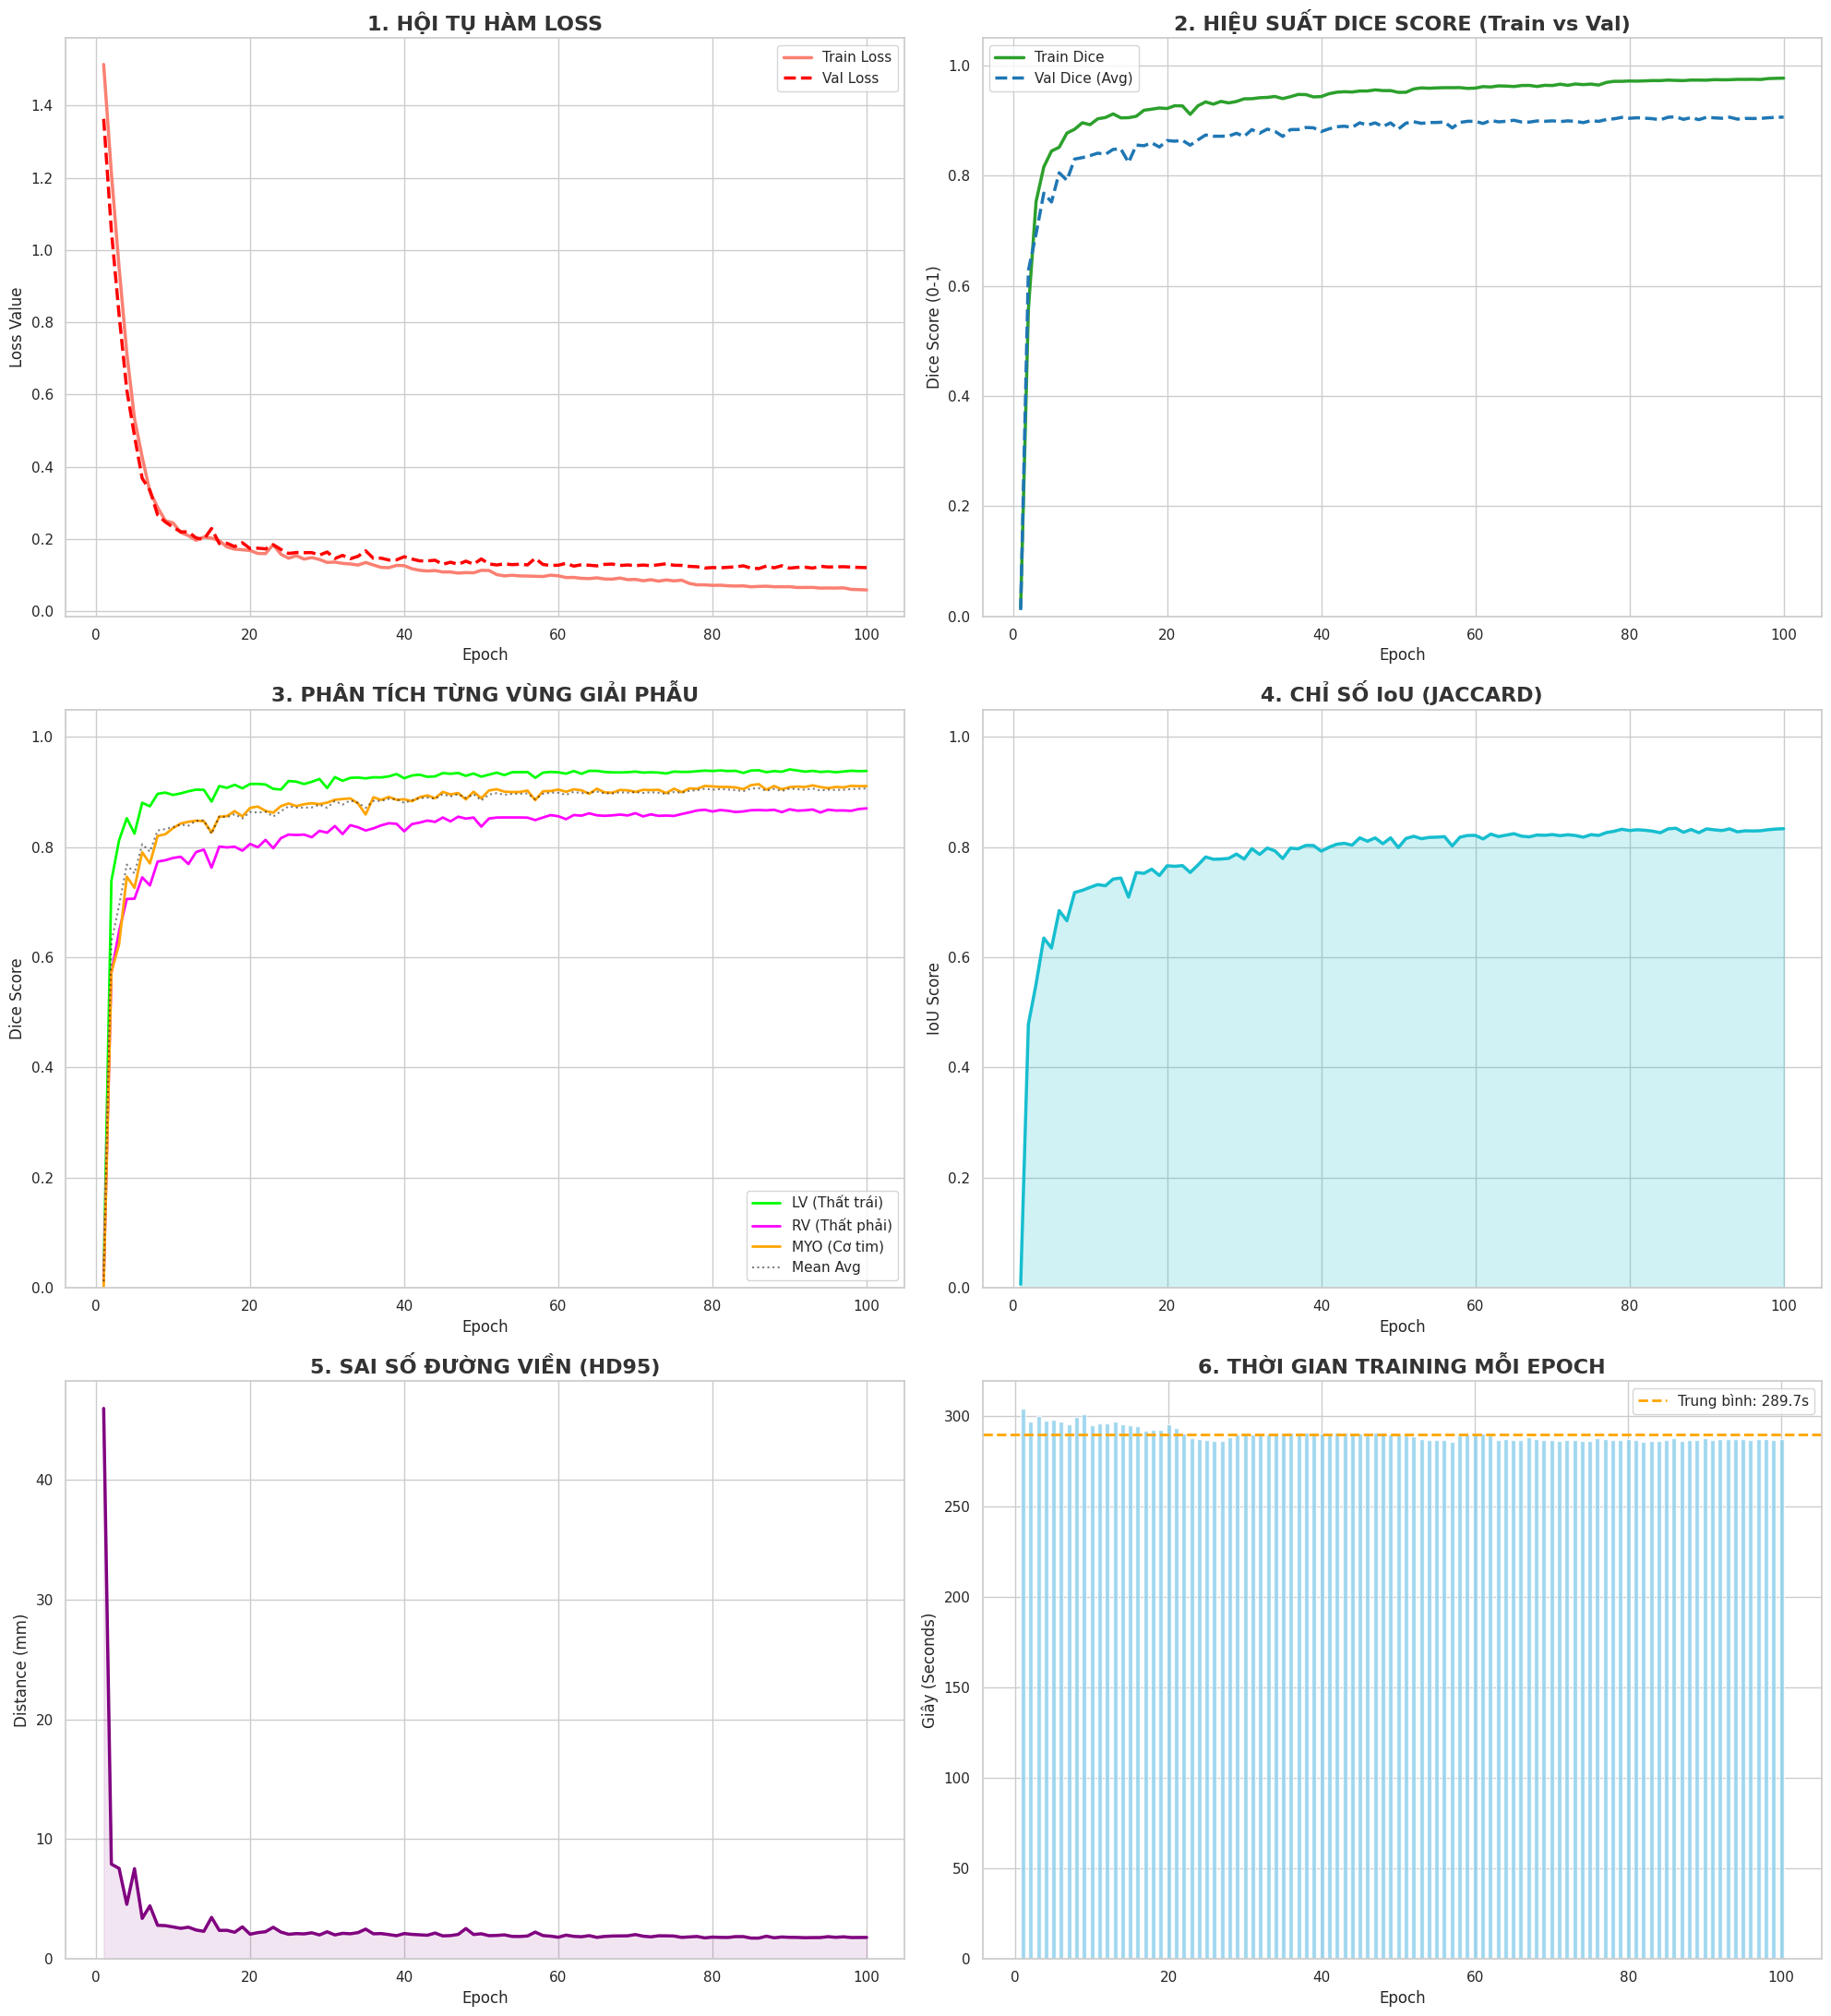

✅ Biểu đồ đã được lưu tại: segresnet3d_final_results/final_dashboard.png

            BÁO CÁO KẾT QUẢ MÔ HÌNH SEGRESNET-3D            
🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: 86
  > Dice Score (Trung bình)   :     0.9072
  > IoU (Jaccard)             :     0.8344
  > HD95 (Sai số biên)        :    1.75 mm
  > -----------------------   :  ---------
  > Dice - Thất trái (LV)     :     0.9397
  > Dice - Thất phải (RV)     :     0.8674
  > Dice - Cơ tim (MYO)       :     0.9145
------------------------------------------------------------
⏳ Tổng thời gian train: 8 giờ 2 phút
📈 Dice cao nhất đạt được: 0.9072


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ================= CẤU HÌNH ĐƯỜNG DẪN (ĐÃ SỬA LỖI) =================
# Dùng Path() để đảm bảo biến này có thuộc tính .exists()
SAVE_DIR = Path("./segresnet3d_final_results")
LOG_PATH = Path("/kaggle/input/seg-khcrop/segresnet3d_final_results/training_log.csv") 

# ================= 1. HÀM VẼ BIỂU ĐỒ (DASHBOARD) =================
def plot_dashboard_matched(log_path):
    # Kiểm tra file tồn tại
    if not log_path.exists():
        print(f"❌ Lỗi: Không tìm thấy file log tại {log_path}")
        return

    df = pd.read_csv(log_path)
    
    # Thiết lập giao diện Seaborn
    sns.set_theme(style="whitegrid")
    
    # Tạo lưới 3 hàng x 2 cột
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.2)

    # --- BIỂU ĐỒ 1: LOSS (tr_loss vs va_loss) ---
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='tr_loss', label='Train Loss', color='salmon', linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='va_loss', label='Val Loss', color='red', linewidth=2.5, linestyle='--')
    axes[0, 0].set_title('1. HỘI TỤ HÀM LOSS', fontsize=16, fontweight='bold', color='#333333')
    axes[0, 0].set_ylabel('Loss Value')

    # --- BIỂU ĐỒ 2: DICE TỔNG QUÁT (tr_dice vs va_dice) ---
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='tr_dice', label='Train Dice', color='#2ca02c', linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='va_dice', label='Val Dice (Avg)', color='#1f77b4', linewidth=2.5, linestyle='--')
    axes[0, 1].set_title('2. HIỆU SUẤT DICE SCORE (Train vs Val)', fontsize=16, fontweight='bold', color='#333333')
    axes[0, 1].set_ylabel('Dice Score (0-1)')
    axes[0, 1].set_ylim(0, 1.05)

    # --- BIỂU ĐỒ 3: DICE CHI TIẾT (lv_d, rv_d, myo_d) ---
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='lv_d', label='LV (Thất trái)', color='lime', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='rv_d', label='RV (Thất phải)', color='magenta', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='myo_d', label='MYO (Cơ tim)', color='orange', linewidth=2)
    # Đường trung bình mờ
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='va_dice', label='Mean Avg', color='black', linestyle=':', alpha=0.5)
    
    axes[1, 0].set_title('3. PHÂN TÍCH TỪNG VÙNG GIẢI PHẪU', fontsize=16, fontweight='bold', color='#333333')
    axes[1, 0].set_ylabel('Dice Score')
    axes[1, 0].set_ylim(0, 1.05)

    # --- BIỂU ĐỒ 4: IoU (va_iou) ---
    axes[1, 1].fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
    axes[1, 1].plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Mean IoU')
    axes[1, 1].set_title('4. CHỈ SỐ IoU (JACCARD)', fontsize=16, fontweight='bold', color='#333333')
    axes[1, 1].set_ylabel('IoU Score')
    axes[1, 1].set_ylim(0, 1.05)

    # --- BIỂU ĐỒ 5: HD95 (va_hd95) ---
    sns.lineplot(ax=axes[2, 0], data=df, x='epoch', y='va_hd95', color='purple', linewidth=2.5)
    axes[2, 0].fill_between(df['epoch'], df['va_hd95'], color='purple', alpha=0.1)
    axes[2, 0].set_title('5. SAI SỐ ĐƯỜNG VIỀN (HD95)', fontsize=16, fontweight='bold', color='#333333')
    axes[2, 0].set_ylabel('Distance (mm)')
    axes[2, 0].set_ylim(bottom=0)

    # --- BIỂU ĐỒ 6: THỜI GIAN (time) ---
    axes[2, 1].bar(df['epoch'], df['time'], color='skyblue', alpha=0.8, width=0.6)
    avg_time = df['time'].mean()
    axes[2, 1].axhline(avg_time, color='orange', linestyle='--', linewidth=2, label=f'Trung bình: {avg_time:.1f}s')
    axes[2, 1].set_title('6. THỜI GIAN TRAINING MỖI EPOCH', fontsize=16, fontweight='bold', color='#333333')
    axes[2, 1].set_ylabel('Giây (Seconds)')
    axes[2, 1].legend()

    # Label chung trục X
    for ax in axes.flat:
        ax.set_xlabel('Epoch', fontsize=12)

    # Lưu và hiển thị
    plt.tight_layout()
    save_path = SAVE_DIR / "final_dashboard.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Biểu đồ đã được lưu tại: {save_path}")

# ================= 2. HÀM BÁO CÁO SỐ LIỆU (REPORT) =================
def print_report_matched(log_path):
    if not log_path.exists(): return
    df = pd.read_csv(log_path)
    
    # Tìm Epoch tốt nhất dựa trên cột 'va_dice'
    best_idx = df['va_dice'].idxmax()
    best_row = df.iloc[best_idx]
    
    # Tính thời gian
    total_seconds = df['time'].sum()
    hours = int(total_seconds // 3600)
    minutes = int((total_seconds % 3600) // 60)

    print("\n" + "="*60)
    print(f"{'BÁO CÁO KẾT QUẢ MÔ HÌNH SEGRESNET-3D':^60}")
    print("="*60)
    
    print(f"🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: {int(best_row['epoch'])}")
    
    # Map đúng tên cột của bạn vào bảng
    data_table = [
        ["Dice Score (Trung bình)", f"{best_row['va_dice']:.4f}"],
        ["IoU (Jaccard)",           f"{best_row['va_iou']:.4f}"],
        ["HD95 (Sai số biên)",      f"{best_row['va_hd95']:.2f} mm"],
        ["-----------------------", "---------"],
        ["Dice - Thất trái (LV)",   f"{best_row['lv_d']:.4f}"],
        ["Dice - Thất phải (RV)",   f"{best_row['rv_d']:.4f}"],
        ["Dice - Cơ tim (MYO)",     f"{best_row['myo_d']:.4f}"],
    ]
    
    for label, val in data_table:
        print(f"  > {label:<25} : {val:>10}")

    print("-" * 60)
    print(f"⏳ Tổng thời gian train: {hours} giờ {minutes} phút")
    print(f"📈 Dice cao nhất đạt được: {df['va_dice'].max():.4f}")
    print("="*60)

# ================= THỰC THI =================
# Kiểm tra lại lần cuối
if LOG_PATH.exists():
    plot_dashboard_matched(LOG_PATH)
    print_report_matched(LOG_PATH)
else:
    print(f"⚠️ Chưa tìm thấy file {LOG_PATH}. Hãy chạy Training xong rồi quay lại chạy cell này nhé!")

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path  # <--- Quan trọng: Import thư viện Path

# ================= CẤU HÌNH (SỬA LỖI TẠI ĐÂY) =================
# Bọc đường dẫn trong hàm Path() để biến nó thành đối tượng Path
SAVE_DIR = Path("./segresnet3d_final_results")
LOG_PATH = SAVE_DIR / "/kaggle/input/seg-khcrop/segresnet3d_final_results/training_log.csv"

# Kiểm tra file (Lúc này .exists() sẽ hoạt động tốt)
if not LOG_PATH.exists():
    print(f"❌ Lỗi: Không tìm thấy file tại {LOG_PATH}")
    print("👉 Hãy kiểm tra xem bạn đã chạy xong bước Training chưa? Hoặc sai đường dẫn folder.")
else:
    # Load dữ liệu
    df = pd.read_csv(LOG_PATH)
    
    # Tìm cột dice phù hợp (đề phòng tên cột thay đổi)
    if 'va_dice' in df.columns:
        col_dice = 'va_dice'
    elif 'va_dice_avg' in df.columns:
        col_dice = 'va_dice_avg'
    else:
        # Nếu không tìm thấy, lấy tạm cột đầu tiên có chữ dice
        col_dice = [c for c in df.columns if 'dice' in c][0]

    # Tìm epoch tốt nhất
    best_idx = df[col_dice].idxmax()
    best_epoch = df.iloc[best_idx]['epoch']
    best_dice = df.iloc[best_idx][col_dice]
    
    print(f"✅ Đã load dữ liệu thành công! (Tổng: {len(df)} epochs)")
    print(f"🏆 Best Epoch: {int(best_epoch)} (Dice: {best_dice:.4f})")

    # Hàm vẽ đường kẻ dọc (dùng cho các cell bên dưới)
    def add_best_epoch_line():
        plt.axvline(best_epoch, color='black', linestyle=':', alpha=0.6, label=f'Best Epoch: {int(best_epoch)}')
        plt.legend()

✅ Đã load dữ liệu thành công! (Tổng: 100 epochs)
🏆 Best Epoch: 86 (Dice: 0.9072)


# **Biểu đồ Loss**

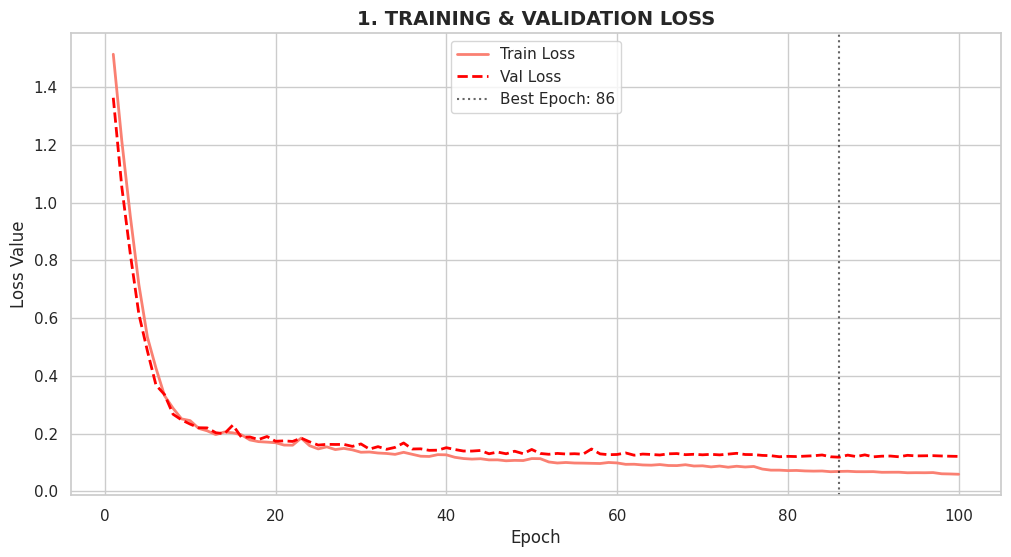

In [4]:
# Cấu hình giao diện
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Vẽ Loss
sns.lineplot(data=df, x='epoch', y='tr_loss', label='Train Loss', color='salmon', linewidth=2)
sns.lineplot(data=df, x='epoch', y='va_loss', label='Val Loss', color='red', linewidth=2, linestyle='--')

# Trang trí
add_best_epoch_line()
plt.title('1. TRAINING & VALIDATION LOSS', fontsize=14, fontweight='bold')
plt.ylabel('Loss Value')
plt.xlabel('Epoch')

plt.show()

# **Biểu đồ Dice**

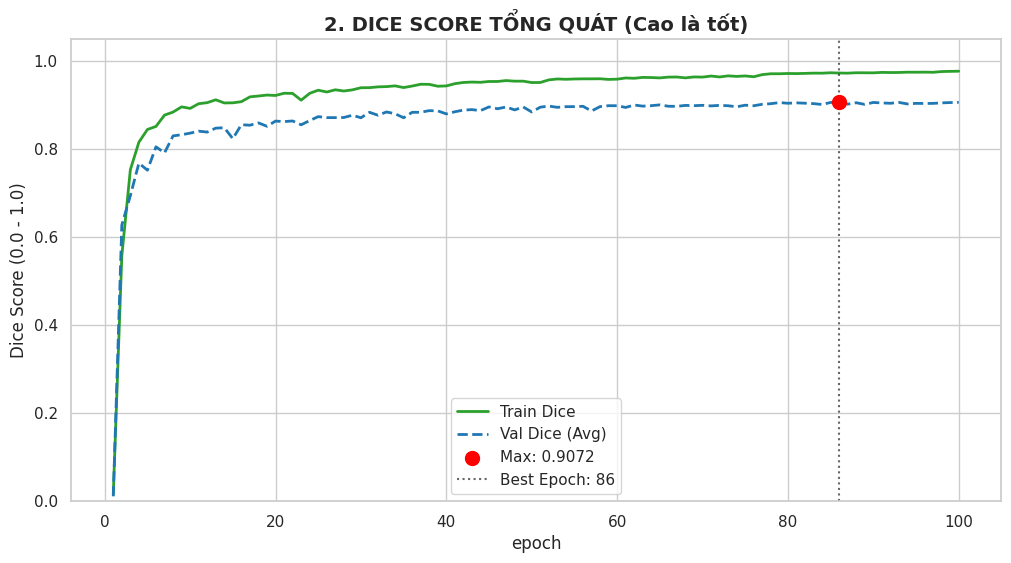

In [16]:
plt.figure(figsize=(12, 6))

# Vẽ Dice
sns.lineplot(data=df, x='epoch', y='tr_dice', label='Train Dice', color='#2ca02c', linewidth=2)
sns.lineplot(data=df, x='epoch', y='va_dice', label='Val Dice (Avg)', color='#1f77b4', linewidth=2, linestyle='--')

# Đánh dấu điểm cao nhất
plt.scatter(best_epoch, best_dice, color='red', zorder=5, s=100, label=f'Max: {best_dice:.4f}')

# Trang trí
add_best_epoch_line()
plt.title('2. DICE SCORE TỔNG QUÁT', fontsize=14, fontweight='bold')
plt.ylabel('Dice Score (0.0 - 1.0)')
plt.ylim(0, 1.05)

plt.show()

# **Biểu đồ Dice Score chi tiết**

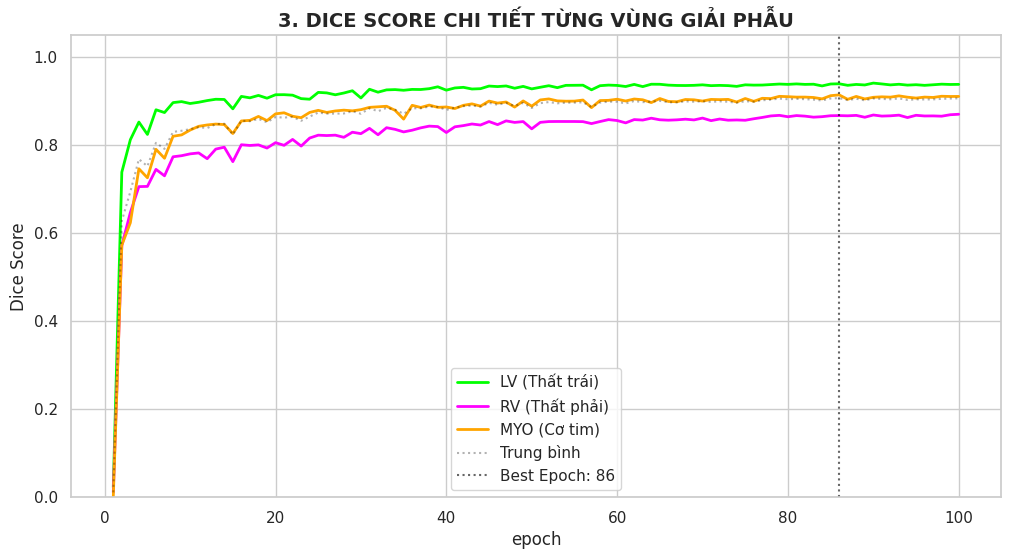

In [17]:
plt.figure(figsize=(12, 6))

# Vẽ từng lớp (Tên cột: lv_d, rv_d, myo_d)
sns.lineplot(data=df, x='epoch', y='lv_d', label='LV (Thất trái)', color='lime', linewidth=2)
sns.lineplot(data=df, x='epoch', y='rv_d', label='RV (Thất phải)', color='magenta', linewidth=2)
sns.lineplot(data=df, x='epoch', y='myo_d', label='MYO (Cơ tim)', color='orange', linewidth=2)

# Vẽ đường trung bình mờ để so sánh
plt.plot(df['epoch'], df['va_dice'], label='Trung bình', color='black', linestyle=':', alpha=0.3)

# Trang trí
add_best_epoch_line()
plt.title('3. DICE SCORE CHI TIẾT TỪNG VÙNG GIẢI PHẪU', fontsize=14, fontweight='bold')
plt.ylabel('Dice Score')
plt.ylim(0, 1.05)

plt.show()

# **Biểu đồ chỉ số IoU**

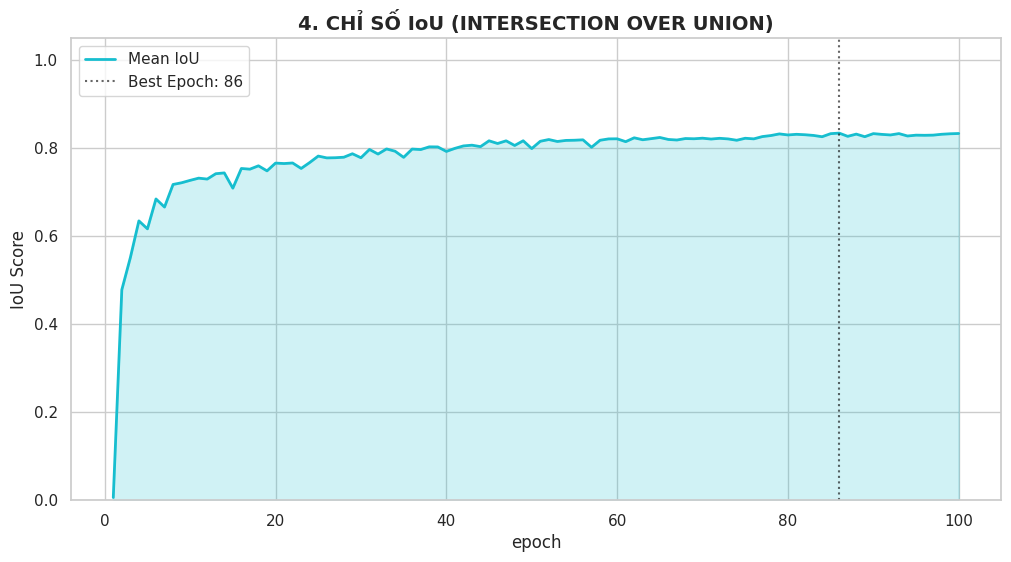

In [18]:
plt.figure(figsize=(12, 6))

# Vẽ IoU
plt.fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
sns.lineplot(data=df, x='epoch', y='va_iou', label='Mean IoU', color='#17becf', linewidth=2)

# Trang trí
add_best_epoch_line()
plt.title('4. CHỈ SỐ IoU (INTERSECTION OVER UNION)', fontsize=14, fontweight='bold')
plt.ylabel('IoU Score')
plt.ylim(0, 1.05)

plt.show()

# **Biểu đồ HD95**

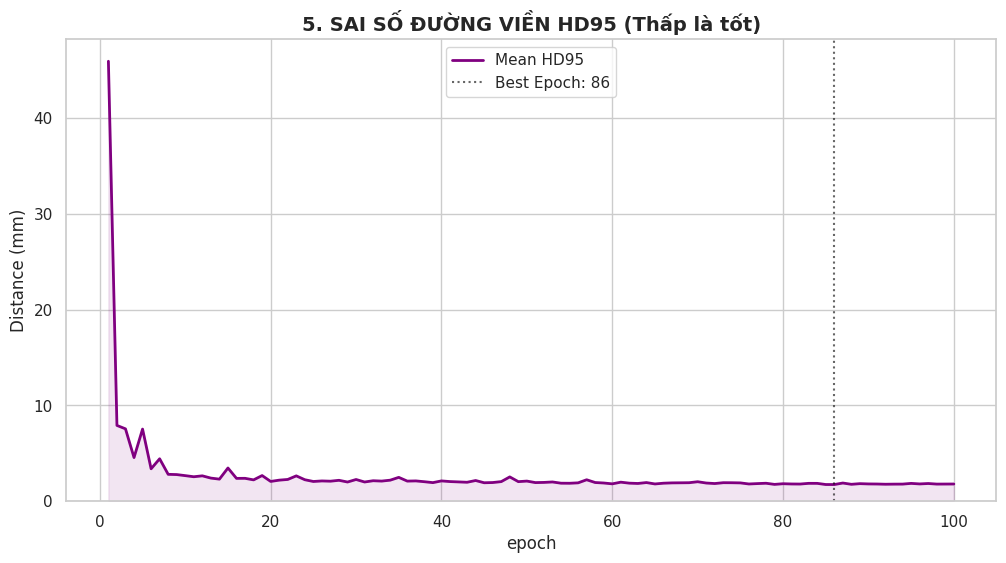

In [19]:
plt.figure(figsize=(12, 6))

# Vẽ HD95
plt.fill_between(df['epoch'], df['va_hd95'], color='purple', alpha=0.1)
sns.lineplot(data=df, x='epoch', y='va_hd95', label='Mean HD95', color='purple', linewidth=2)

# Trang trí
add_best_epoch_line()
plt.title('5. SAI SỐ ĐƯỜNG VIỀN HD95 (Thấp là tốt)', fontsize=14, fontweight='bold')
plt.ylabel('Distance (mm)')
plt.ylim(bottom=0) 

plt.show()

# **Biểu đồ thời gian huấn luyện**

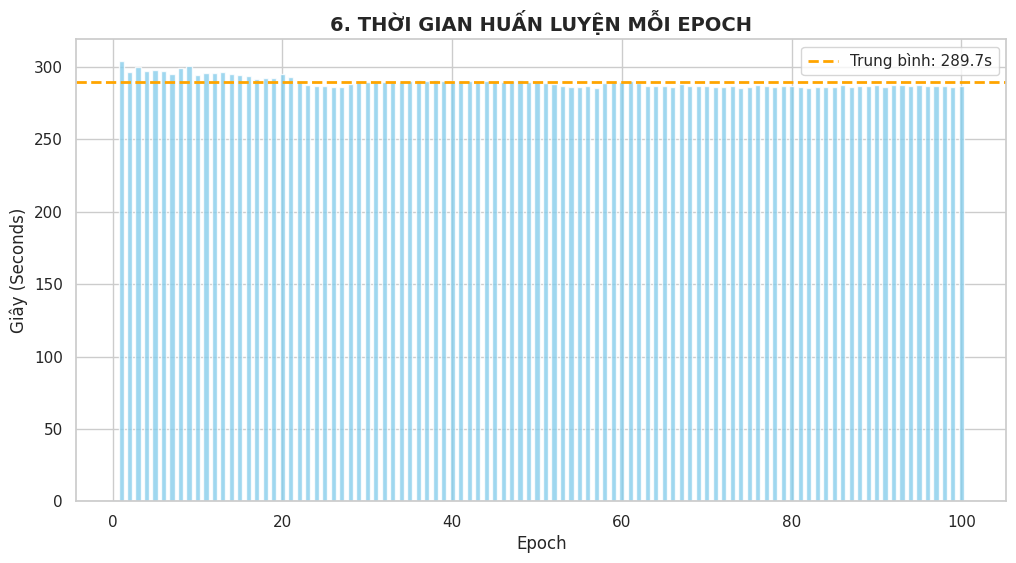

In [20]:
plt.figure(figsize=(12, 6))

# Vẽ cột thời gian
plt.bar(df['epoch'], df['time'], color='skyblue', alpha=0.8, width=0.6)

# Vẽ đường trung bình
avg_time = df['time'].mean()
plt.axhline(avg_time, color='orange', linestyle='--', linewidth=2, label=f'Trung bình: {avg_time:.1f}s')

# Trang trí
plt.title('6. THỜI GIAN HUẤN LUYỆN MỖI EPOCH', fontsize=14, fontweight='bold')
plt.ylabel('Giây (Seconds)')
plt.xlabel('Epoch')
plt.legend()

plt.show()

# **Đánh giá định lượng trên tập Test**

In [28]:
# -------------------------------------------------------------------------
# CELL 9: ĐÁNH GIÁ ĐỊNH LƯỢNG TRÊN TẬP TEST (TEST SET EVALUATION)
# -------------------------------------------------------------------------
from torch.utils.data import DataLoader
from monai.data import Dataset
import numpy as np
import torch
from tqdm.auto import tqdm

model_path = SAVE_DIR / "/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth"
if model_path.exists():
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    print(f"✅ Đã load weights từ: {model_path}")
else:
    print(f"❌ Chưa tìm thấy file weights tại {model_path}")

model.eval()

# 2. Tạo Test Loader (Sử dụng đúng VolumeDataset của bạn để Resize chuẩn)
# augment=False để không lật ảnh lung tung
test_dataset = VolumeDataset(te_items, augment=False) 
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# 3. Khởi tạo biến lưu trữ kết quả
# Cấu trúc: {'LV': {'dice': [], 'iou': [], 'hd95': []}, ...}
metrics_storage = {
    'LV': {'dice': [], 'iou': [], 'hd95': []},
    'RV': {'dice': [], 'iou': [], 'hd95': []},
    'MYO': {'dice': [], 'iou': [], 'hd95': []}
}
overall_metrics = {'dice': [], 'iou': [], 'hd95': []}

print(f"🚀 Đang đánh giá trên {len(te_items)} mẫu tập Test...")

with torch.no_grad():
    for batch in tqdm(test_loader):
        # Lấy dữ liệu và đưa lên GPU
        img = batch["image"].to(DEVICE)
        lab = batch["label"].to(DEVICE)
        
        # Inference (Dự đoán)
        out = model(img)
        
        # Xử lý kết quả:
        # out shape: (1, 4, D, H, W) -> argmax -> (1, D, H, W) -> numpy -> (D, H, W)
        p = torch.argmax(out, dim=1).cpu().numpy()[0]
        g = lab.cpu().numpy()[0]
        
        # Tính metrics bằng hàm get_metrics của bạn
        # m trả về: {'LV': (dice, jc, hd95), 'RV': ..., 'MYO': ...}
        m = get_metrics(p, g)
        
        # Biến tạm để tính trung bình cho mẫu hiện tại
        sample_dices = []
        sample_ious = []
        sample_hds = []
        
        # Lưu lại từng lớp
        for cls_name in ['LV', 'RV', 'MYO']:
            d, i, h = m[cls_name]
            
            metrics_storage[cls_name]['dice'].append(d)
            metrics_storage[cls_name]['iou'].append(i)
            metrics_storage[cls_name]['hd95'].append(h)
            
            sample_dices.append(d)
            sample_ious.append(i)
            sample_hds.append(h)
        
        # Tính trung bình cộng (Average) cho mẫu này (Overall)
        overall_metrics['dice'].append(np.mean(sample_dices))
        overall_metrics['iou'].append(np.mean(sample_ious))
        overall_metrics['hd95'].append(np.mean(sample_hds))

# 4. In Báo Cáo Kết Quả
print("\n" + "="*65)
print(f"{'KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST':^65}")
print("="*65)

# Tính trung bình toàn bộ tập test
avg_dice = np.mean(overall_metrics['dice'])
avg_iou = np.mean(overall_metrics['iou'])
avg_hd95 = np.mean(overall_metrics['hd95'])

print(f"⭐ Dice Score trung bình (All Classes): {avg_dice:.4f}")
print(f"⭐ IoU trung bình (All Classes):        {avg_iou:.4f}")
print(f"⭐ HD95 trung bình (All Classes):       {avg_hd95:.2f} mm")
print("-" * 65)

# In bảng chi tiết từng lớp
print(f"{'Lớp (Class)':<10} | {'Dice':<10} | {'IoU':<10} | {'HD95 (mm)':<10}")
print("-" * 65)

for cls_name in ['LV', 'RV', 'MYO']:
    d_mean = np.mean(metrics_storage[cls_name]['dice'])
    i_mean = np.mean(metrics_storage[cls_name]['iou'])
    h_mean = np.mean(metrics_storage[cls_name]['hd95'])
    
    print(f"{cls_name:<10} | {d_mean:.4f}     | {i_mean:.4f}     | {h_mean:.2f}")

print("="*65)

✅ Đã load weights từ: /kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth
🚀 Đang đánh giá trên 108 mẫu tập Test...


  0%|          | 0/108 [00:00<?, ?it/s]


            KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST             
⭐ Dice Score trung bình (All Classes): 0.9106
⭐ IoU trung bình (All Classes):        0.8397
⭐ HD95 trung bình (All Classes):       1.70 mm
-----------------------------------------------------------------
Lớp (Class) | Dice       | IoU        | HD95 (mm) 
-----------------------------------------------------------------
LV         | 0.9439     | 0.8960     | 1.67
RV         | 0.8700     | 0.7724     | 1.14
MYO        | 0.9179     | 0.8508     | 2.30



Dang hien thi 6 mau ngau nhien tu tap Test...



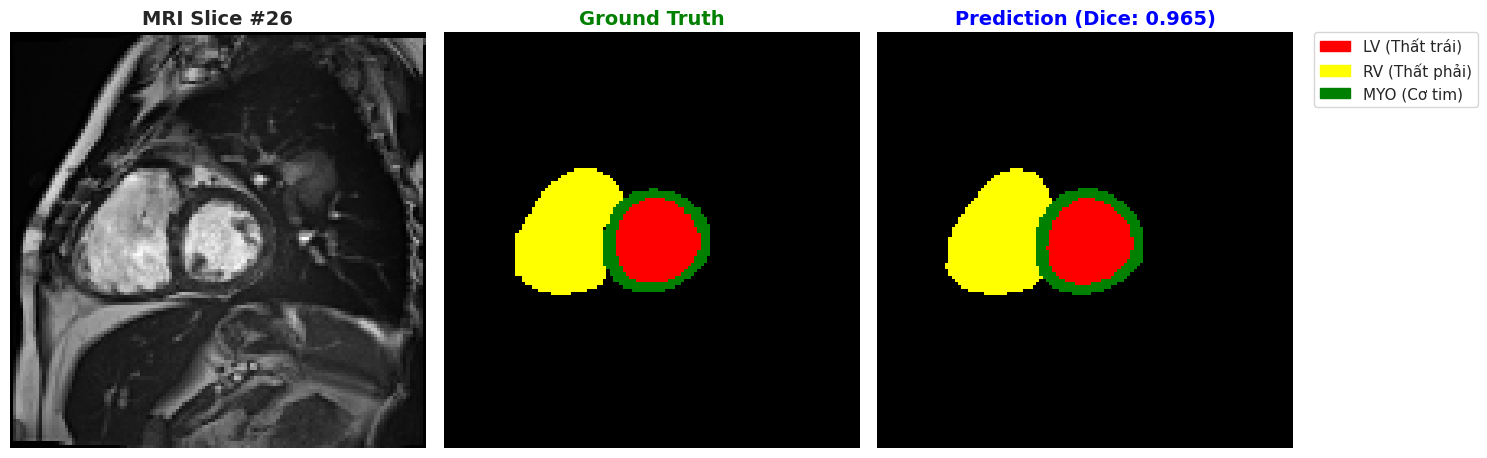

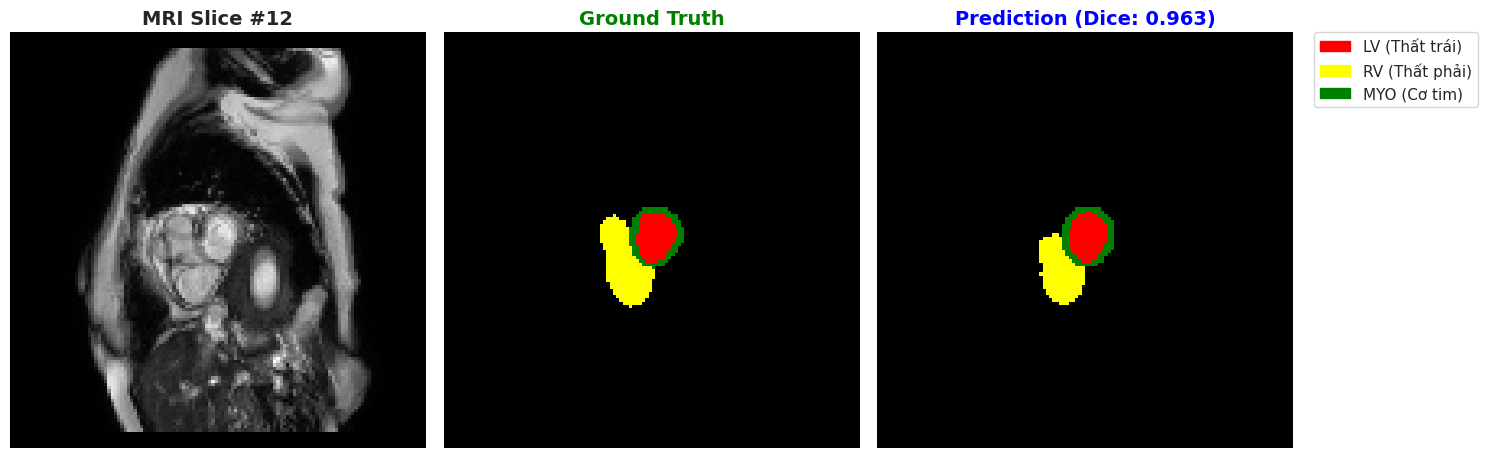

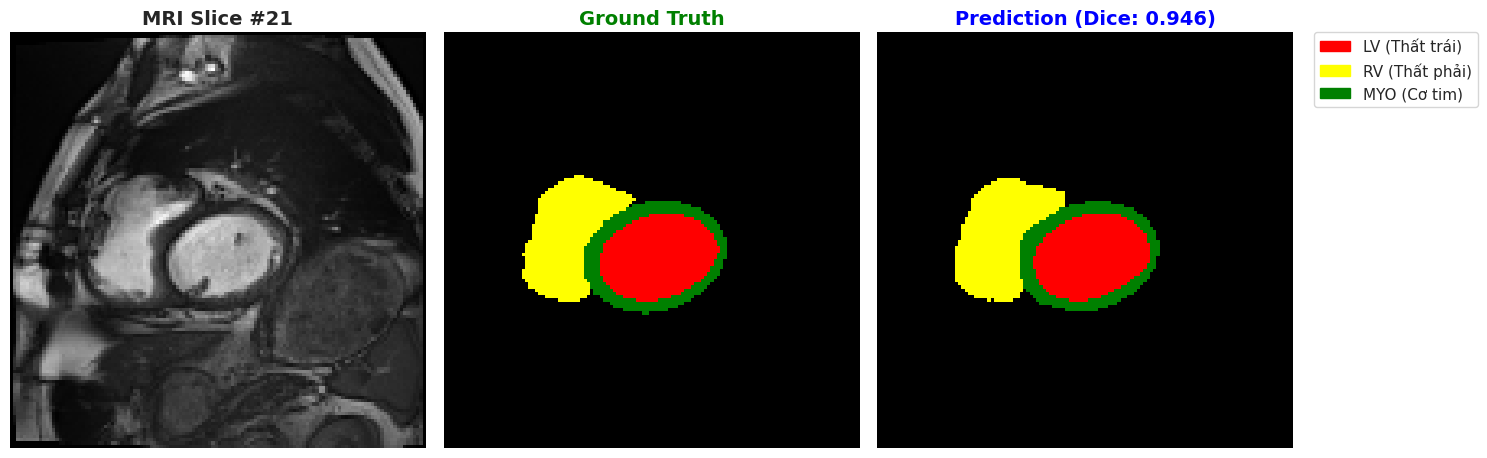

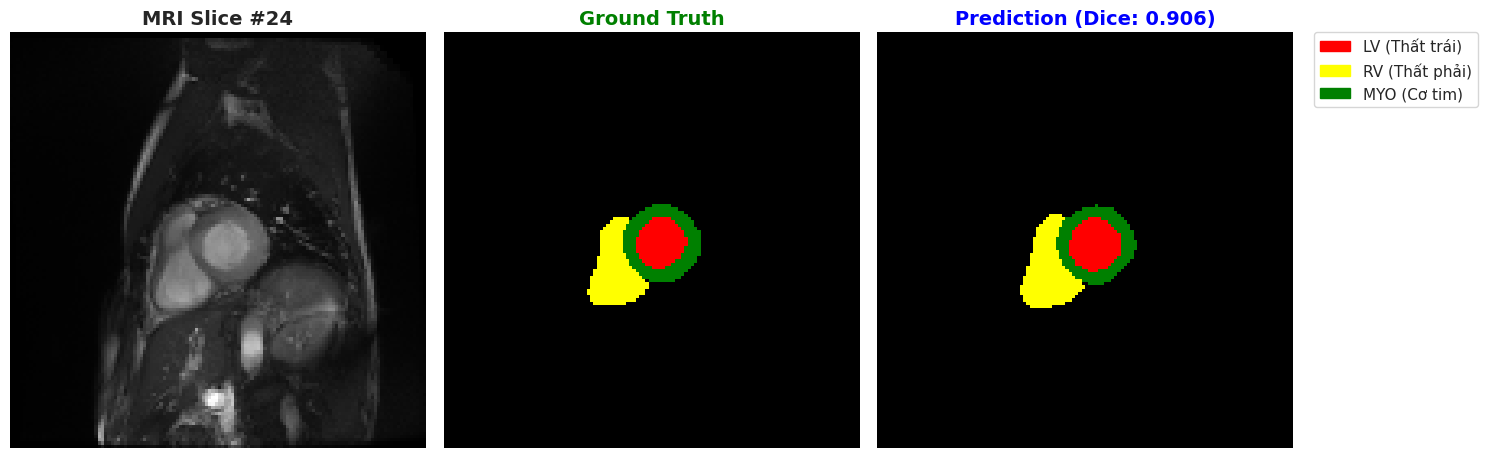

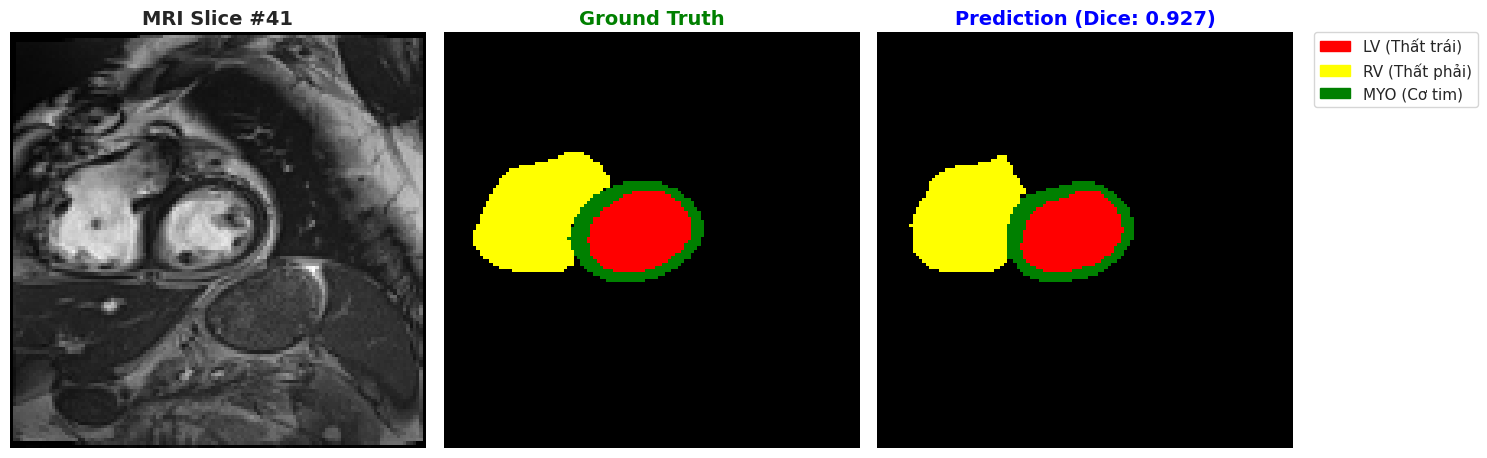

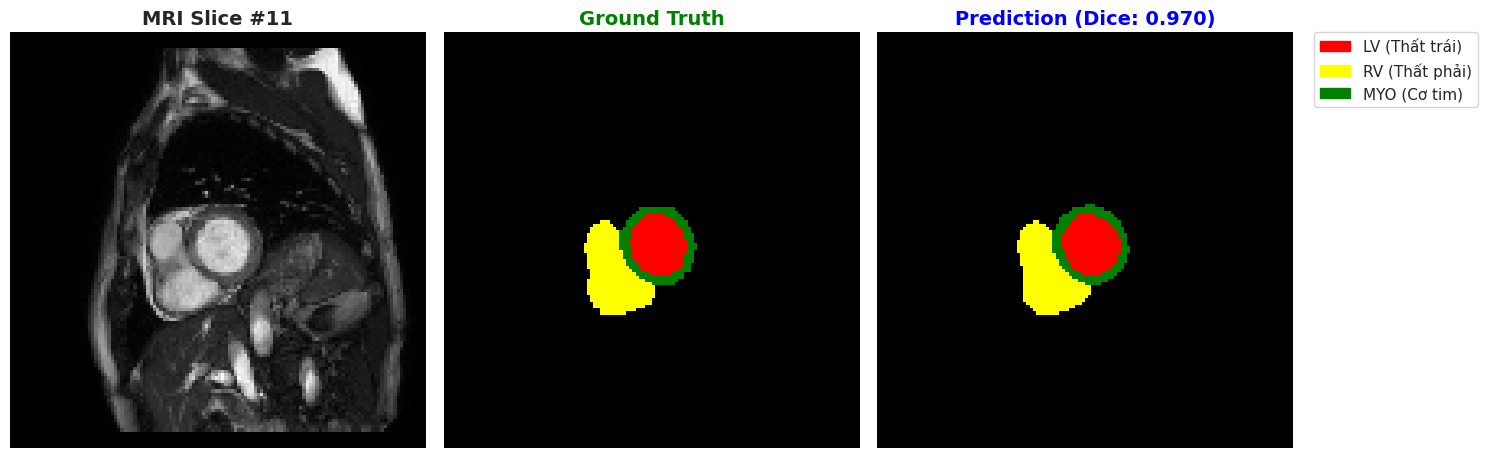

In [39]:
# ---------------- 8. VISUALIZATION ----------------
import matplotlib.patches as mpatches

def visualize_best_worst(model, items, device="cuda", num_samples=3):
    """
    Hàm hiển thị kết quả dự đoán:
    - Load model tốt nhất.
    - Chọn ngẫu nhiên mẫu từ tập test.
    - Tìm lát cắt (slice) có nhiều thông tin nhất (nhiều pixel tim nhất).
    - Vẽ 3 cột: Ảnh gốc - Nhãn thực tế (Ground Truth) - Dự đoán (Prediction).
    """
    # 1. Load lại weight tốt nhất
    chk_path = SAVE_DIR / "/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth"
    if not chk_path.exists():
        print("Chưa tìm thấy file best_model.pth!")
        return
        
    model.load_state_dict(torch.load(chk_path, map_location=device))
    model.eval()
    
    # 2. Định nghĩa màu cho từng lớp (cho đẹp báo cáo)
    # 0: Đen (Nền), 1: Đỏ (LV), 2: Xanh lá (RV), 3: Vàng (MYO)
    colors = ['black', 'red', 'green', 'yellow']
    cmap =  plt.cm.colors.ListedColormap(colors)
    norm =  plt.cm.colors.BoundaryNorm(np.arange(0, 5), cmap.N) 
    
    # Label chú thích
    patches = [
        mpatches.Patch(color='red', label='LV (Thất trái)'),
        mpatches.Patch(color='yellow', label='RV (Thất phải)'),
        mpatches.Patch(color='green', label='MYO (Cơ tim)')
    ]

    # 3. Lấy ngẫu nhiên mẫu test
    sample_indices = random.sample(range(len(items)), min(len(items), num_samples))
    
    ds = VolumeDataset([items[i] for i in sample_indices])
    
    print(f"\nDang hien thi {len(sample_indices)} mau ngau nhien tu tap Test...\n")

    for i in range(len(ds)):
        sample = ds[i]
        img = sample["image"].unsqueeze(0).to(device) # [1, 1, 128, 128, 64]
        gt  = sample["label"].squeeze().numpy()       # [128, 128, 64]
        
        # Inference
        with torch.no_grad():
            # Dùng sliding window hoặc forward thẳng nếu VRAM đủ (ở đây size 128x128x64 khá nhẹ nên forward thẳng)
            out = model(img)
            pred = torch.argmax(out, dim=1).squeeze().cpu().numpy() # [128, 128, 64]
            
        # 4. Tìm lát cắt đẹp nhất (có diện tích Ground Truth lớn nhất)
        # Để tránh hiển thị các lát cắt ở đỉnh/đáy tim chỉ toàn màu đen
        sums = np.sum(gt > 0, axis=(0, 1)) # Tính tổng pixel tim theo trục Z
        best_slice_idx = np.argmax(sums)   # Lấy index của lát cắt lớn nhất
        
        # Nếu mẫu rỗng (không có tim - hiếm gặp), lấy lát giữa
        if sums[best_slice_idx] == 0:
            best_slice_idx = gt.shape[2] // 2
            
        # Lấy data 2D tại lát cắt đó
        img_show = sample["image"].squeeze().numpy()[:, :, best_slice_idx]
        gt_show  = gt[:, :, best_slice_idx]
        pred_show = pred[:, :, best_slice_idx]
        
        # 5. Tính Dice score riêng cho mẫu này (để hiển thị lên hình)
        # Chỉ tính trên slice này hoặc cả volume (ở đây tính cả volume cho chính xác)
        dc_val = dc(pred > 0, gt > 0) 

        # --- VẼ HÌNH ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Cột 1: Ảnh gốc MRI
        axes[0].imshow(img_show, cmap="gray")
        axes[0].set_title(f"MRI Slice #{best_slice_idx}", fontsize=14, fontweight='bold')
        axes[0].axis('off')
        
        # Cột 2: Ground Truth
        axes[1].imshow(gt_show, cmap=cmap, norm=norm, interpolation='nearest')
        axes[1].set_title("Ground Truth", fontsize=14, fontweight='bold', color='green')
        axes[1].axis('off')
        
        # Cột 3: Prediction
        axes[2].imshow(pred_show, cmap=cmap, norm=norm, interpolation='nearest')
        axes[2].set_title(f"Prediction (Dice: {dc_val:.3f})", fontsize=14, fontweight='bold', color='blue')
        axes[2].axis('off')
        
        # Thêm chú thích màu
        plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
        
        plt.tight_layout()
        plt.show()

# --- GỌI HÀM ---
# Sử dụng biến 'te_items' (tập test) và 'model' đã có từ cell trước
visualize_best_worst(model, te_items, device=DEVICE, num_samples=6)


Hiển thị 6 mẫu (Đã sửa chú thích MYO/RV)...



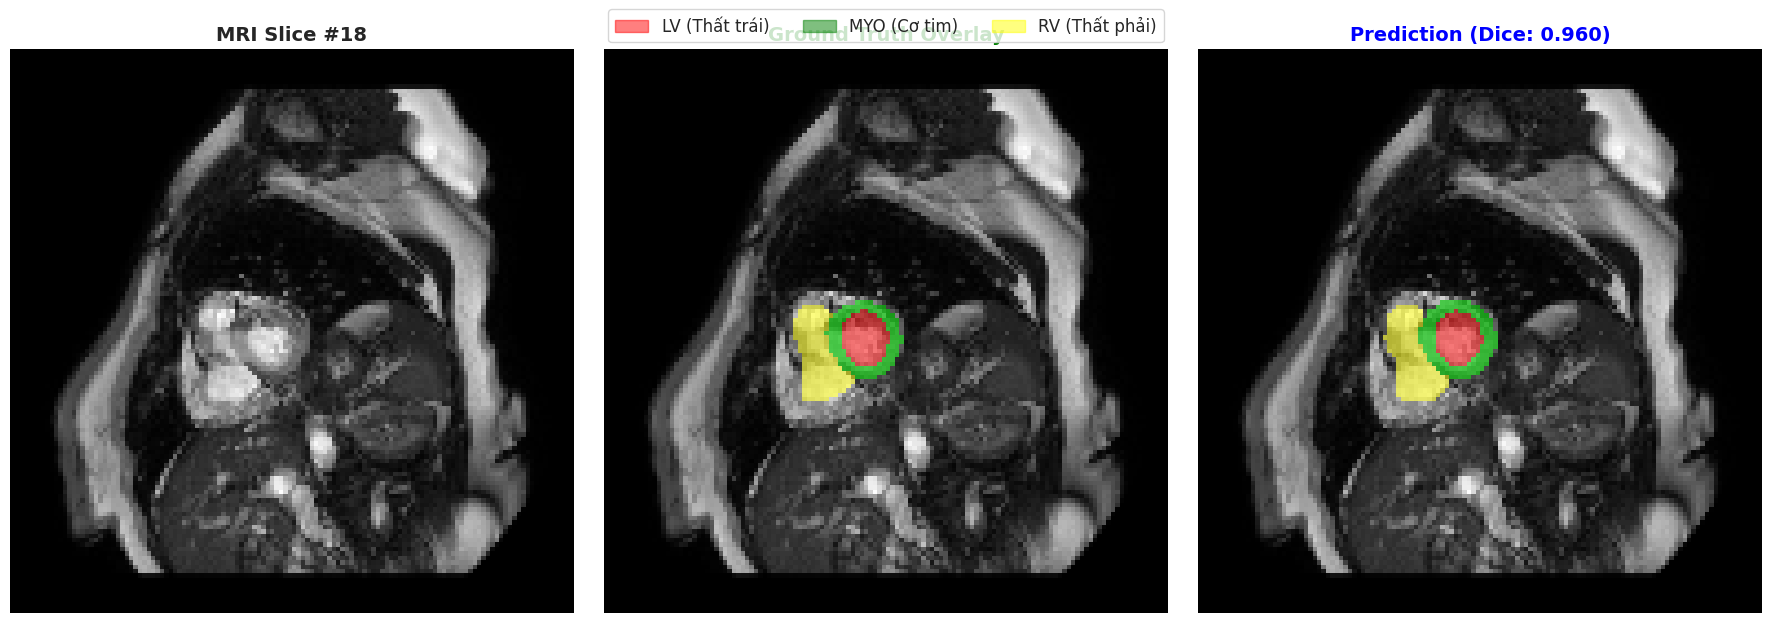

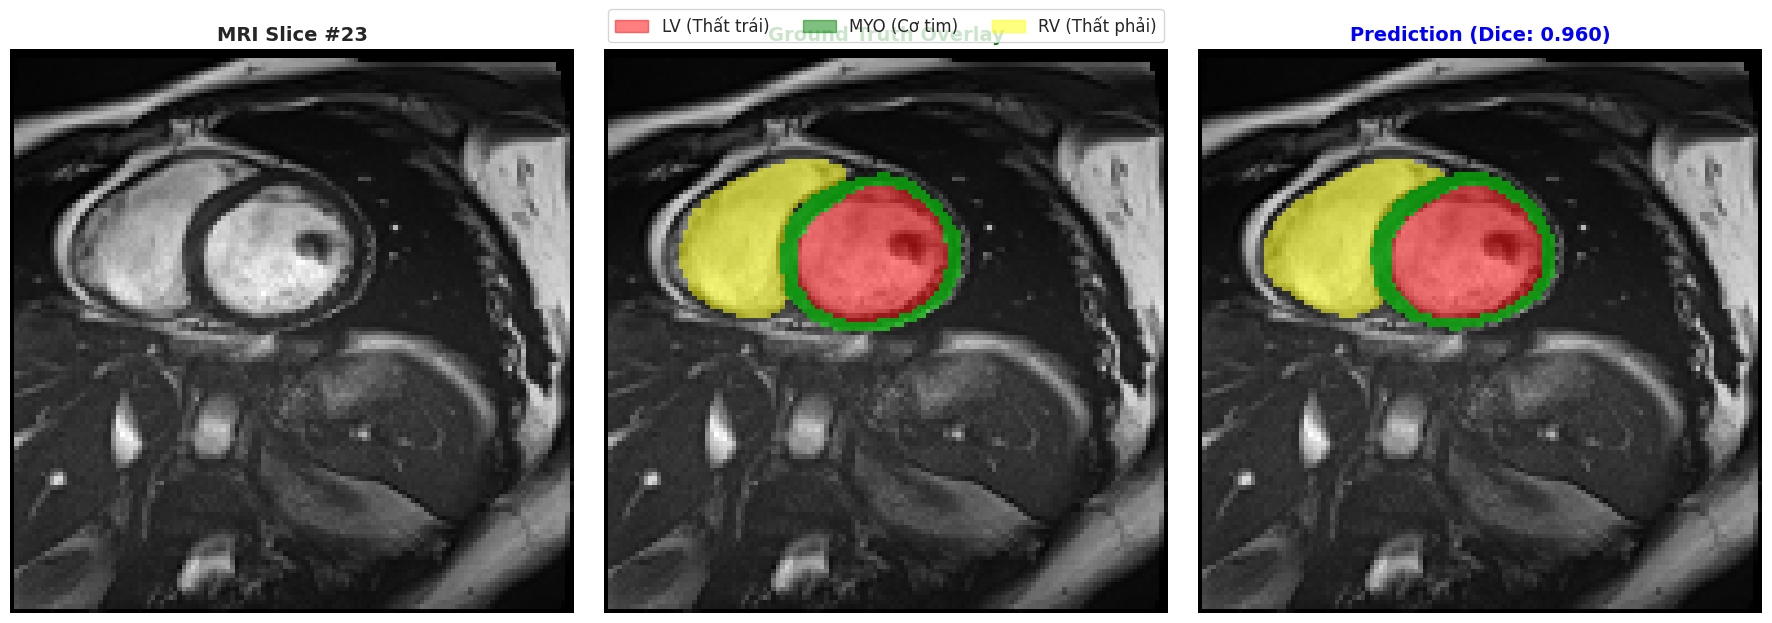

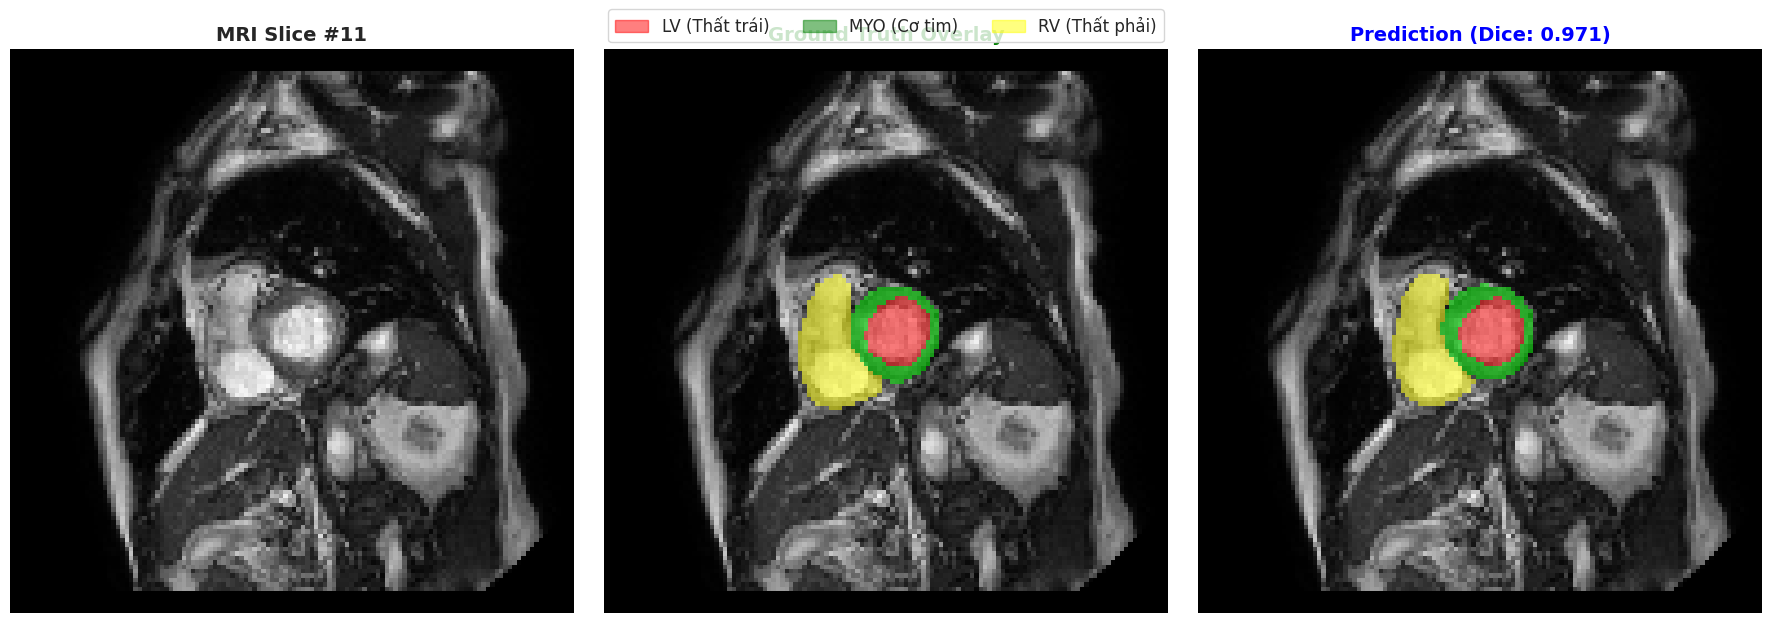

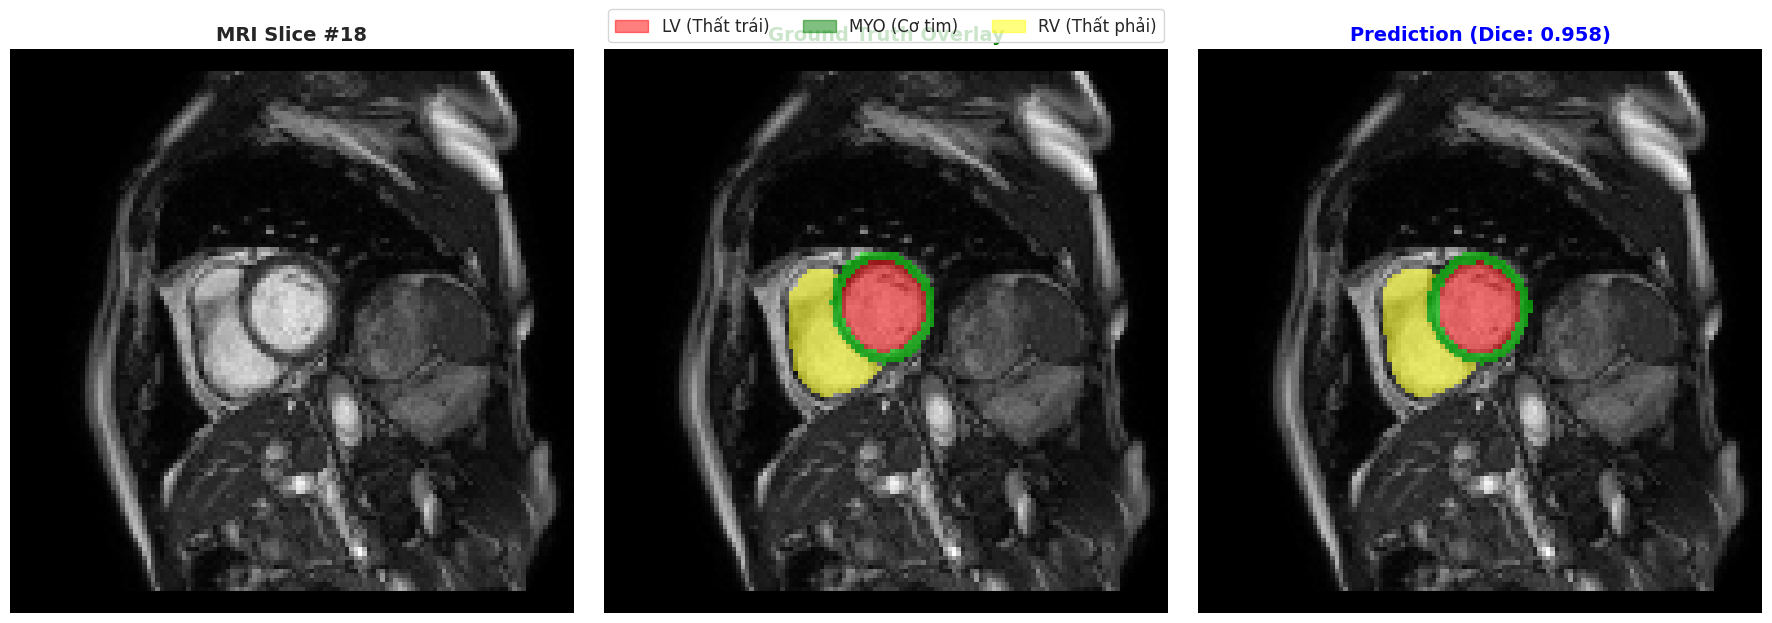

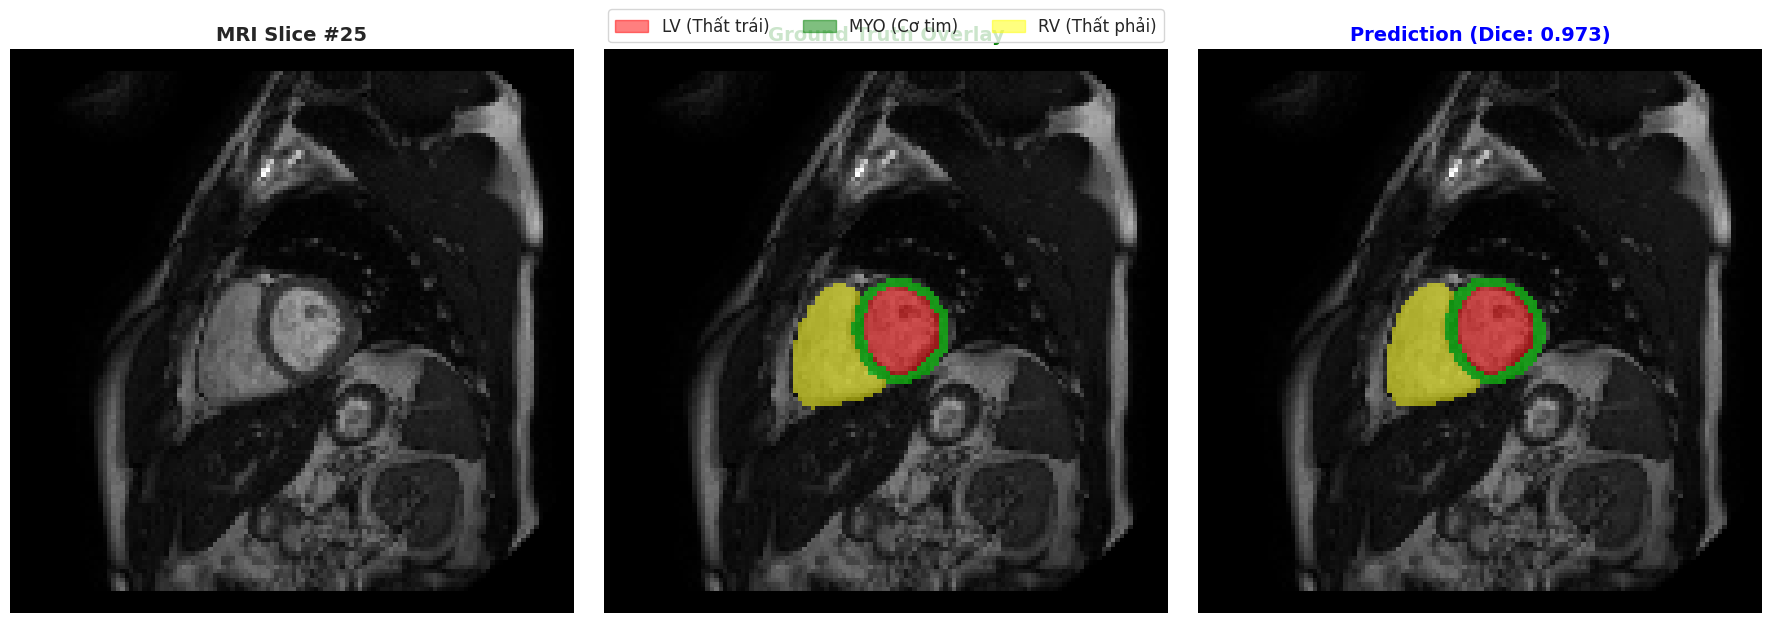

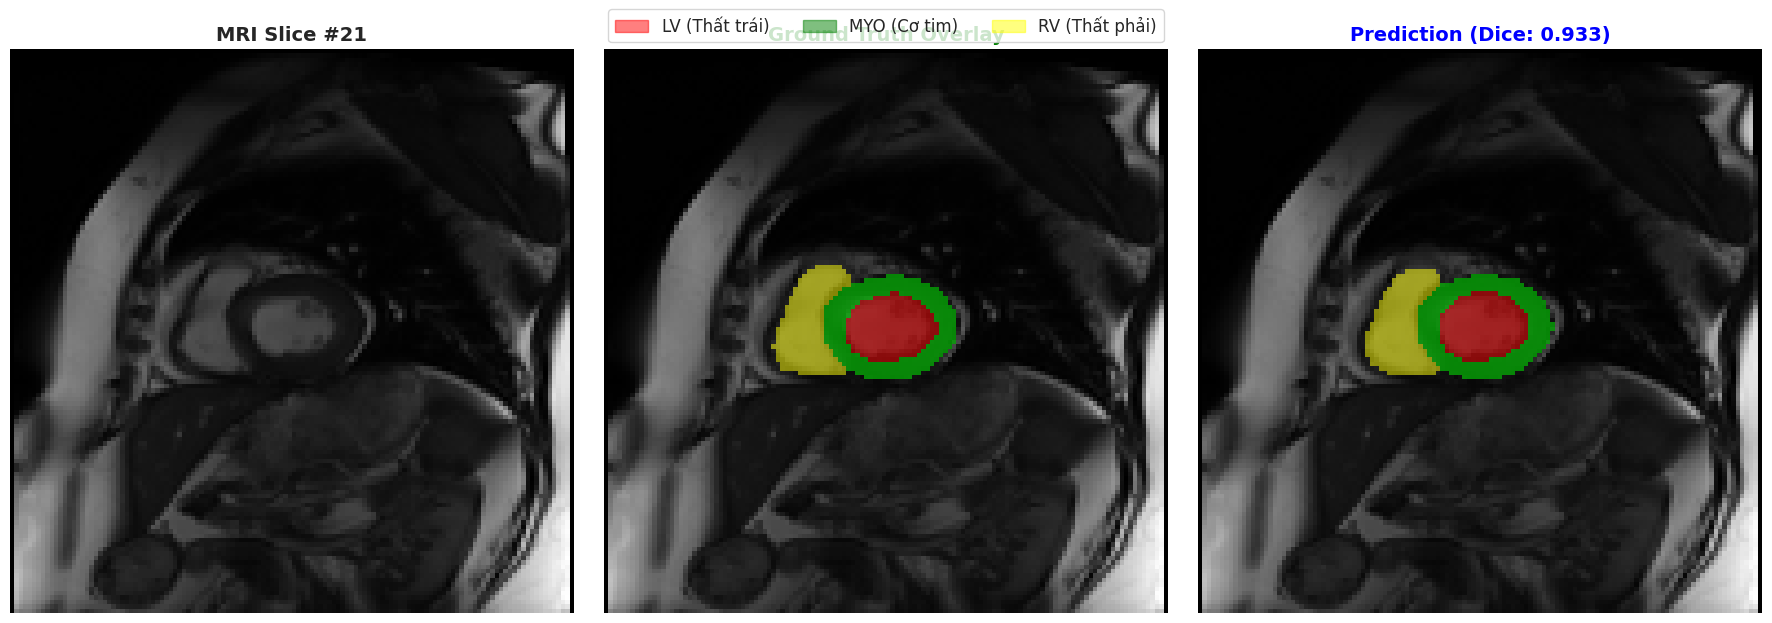

In [38]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
import torch
import random
from medpy.metric.binary import dc

# --- 1. CẤU HÌNH BẢNG MÀU ---
# Class 0: Trong suốt
# Class 1: Đỏ (LV)
# Class 2: Xanh lá (MYO - Cơ tim) -> Đã sửa đúng chuẩn
# Class 3: Vàng (RV - Thất phải) -> Đã sửa đúng chuẩn
cmap_overlay = ListedColormap([
    (0, 0, 0, 0),       # Class 0: Nền trong suốt
    (1, 0, 0, 0.5),     # Class 1: LV - Đỏ
    (0, 1, 0, 0.5),     # Class 2: MYO - Xanh lá
    (1, 1, 0, 0.5)      # Class 3: RV - Vàng
])

def visualize_3_columns_fixed(model, items, device="cuda", num_samples=3):
    """
    Hiển thị 3 cột: MRI Gốc | Ground Truth Overlay | Prediction Overlay
    Đã sửa lại chú thích (Legend) cho đúng thứ tự giải phẫu.
    """
    # Load Model
    chk_path = SAVE_DIR / "best_model.pth"
    if not chk_path.exists():
        chk_path = Path("/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth")
    
    if not chk_path.exists():
        print("Không tìm thấy file best_model.pth")
        return

    model.load_state_dict(torch.load(chk_path, map_location=device))
    model.eval()

    # --- [SỬA LỖI] CHÚ THÍCH ĐÚNG CHUẨN ---
    # Class 1 (Red)    = LV (Thất trái)
    # Class 2 (Green)  = MYO (Cơ tim)  <-- Đã đổi lại dòng này
    # Class 3 (Yellow) = RV (Thất phải) <-- Đã đổi lại dòng này
    patches = [
        mpatches.Patch(color='red', alpha=0.5, label='LV (Thất trái)'),
        mpatches.Patch(color='green', alpha=0.5, label='MYO (Cơ tim)'),
        mpatches.Patch(color='yellow', alpha=0.5, label='RV (Thất phải)')
    ]

    # Chọn mẫu ngẫu nhiên
    indices = random.sample(range(len(items)), min(len(items), num_samples))
    ds = VolumeDataset([items[i] for i in indices])

    print(f"\nHiển thị {len(indices)} mẫu (Đã sửa chú thích MYO/RV)...\n")

    for i in range(len(ds)):
        sample = ds[i]
        img_tensor = sample["image"].unsqueeze(0).to(device)
        gt_vol = sample["label"].squeeze().numpy()

        with torch.no_grad():
            out = model(img_tensor)
            pred_vol = torch.argmax(out, dim=1).squeeze().cpu().numpy()

        # Tìm slice đẹp nhất
        sums = np.sum(gt_vol > 0, axis=(0, 1))
        best_slice = np.argmax(sums) if np.max(sums) > 0 else gt_vol.shape[2] // 2

        img_slice = sample["image"].squeeze().numpy()[:, :, best_slice]
        gt_slice = gt_vol[:, :, best_slice]
        pred_slice = pred_vol[:, :, best_slice]
        
        d_val = dc(pred_vol > 0, gt_vol > 0)

        # Vẽ hình
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        # Cột 1: MRI Gốc
        axes[0].imshow(img_slice, cmap='gray')
        axes[0].set_title(f"MRI Slice #{best_slice}", fontsize=14, fontweight='bold')
        axes[0].axis('off')

        # Cột 2: Ground Truth
        axes[1].imshow(img_slice, cmap='gray')
        axes[1].imshow(gt_slice, cmap=cmap_overlay, vmin=0, vmax=3, interpolation='nearest')
        axes[1].set_title("Ground Truth Overlay", fontsize=14, fontweight='bold', color='green')
        axes[1].axis('off')

        # Cột 3: Prediction
        axes[2].imshow(img_slice, cmap='gray')
        axes[2].imshow(pred_slice, cmap=cmap_overlay, vmin=0, vmax=3, interpolation='nearest')
        axes[2].set_title(f"Prediction (Dice: {d_val:.3f})", fontsize=14, fontweight='bold', color='blue')
        axes[2].axis('off')

        # Legend
        fig.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3, fontsize=12)
        plt.tight_layout()
        plt.show()

# Gọi hàm mới
visualize_3_columns_fixed(model, te_items, device=DEVICE, num_samples=6)

# **Lớp hỗ trợ xây dựng gradCAM**

In [43]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random

# ==============================================================================
# 1. CLASS GRAD-CAM 3D (CORE ENGINE)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        
        # Đăng ký hook để "nghe lén" dữ liệu khi chạy qua layer này
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        """Quan trọng: Gỡ bỏ hook để giải phóng bộ nhớ"""
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx):
        # Reset gradient cũ
        self.model.zero_grad()
        
        # 1. Forward Pass
        output = self.model(input_tensor)
        
        # 2. Backward Pass: Chỉ quan tâm đến Class đích (class_idx)
        # Tính tổng điểm dự đoán của class đó để tìm gradient ngược về
        score = output[0, class_idx].sum()
        score.backward(retain_graph=True)

        # 3. Tạo CAM
        # Global Average Pooling trên gradients (trọng số alpha)
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        
        # Nhân trọng số với activation map
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        
        # ReLU: Chỉ lấy các đặc trưng có ảnh hưởng dương tính (tích cực)
        cam = F.relu(cam).detach().cpu().numpy()
        
        # Chuẩn hóa về [0, 1] để hiển thị
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        
        return cam


🚀 Đang khởi tạo XAI Dashboard cho 6 mẫu...
🎯 Target Layer: Conv3d(32, 4, kernel_size=(1, 1, 1), stride=(1, 1, 1))

>> Đang phân tích mẫu ID: 27


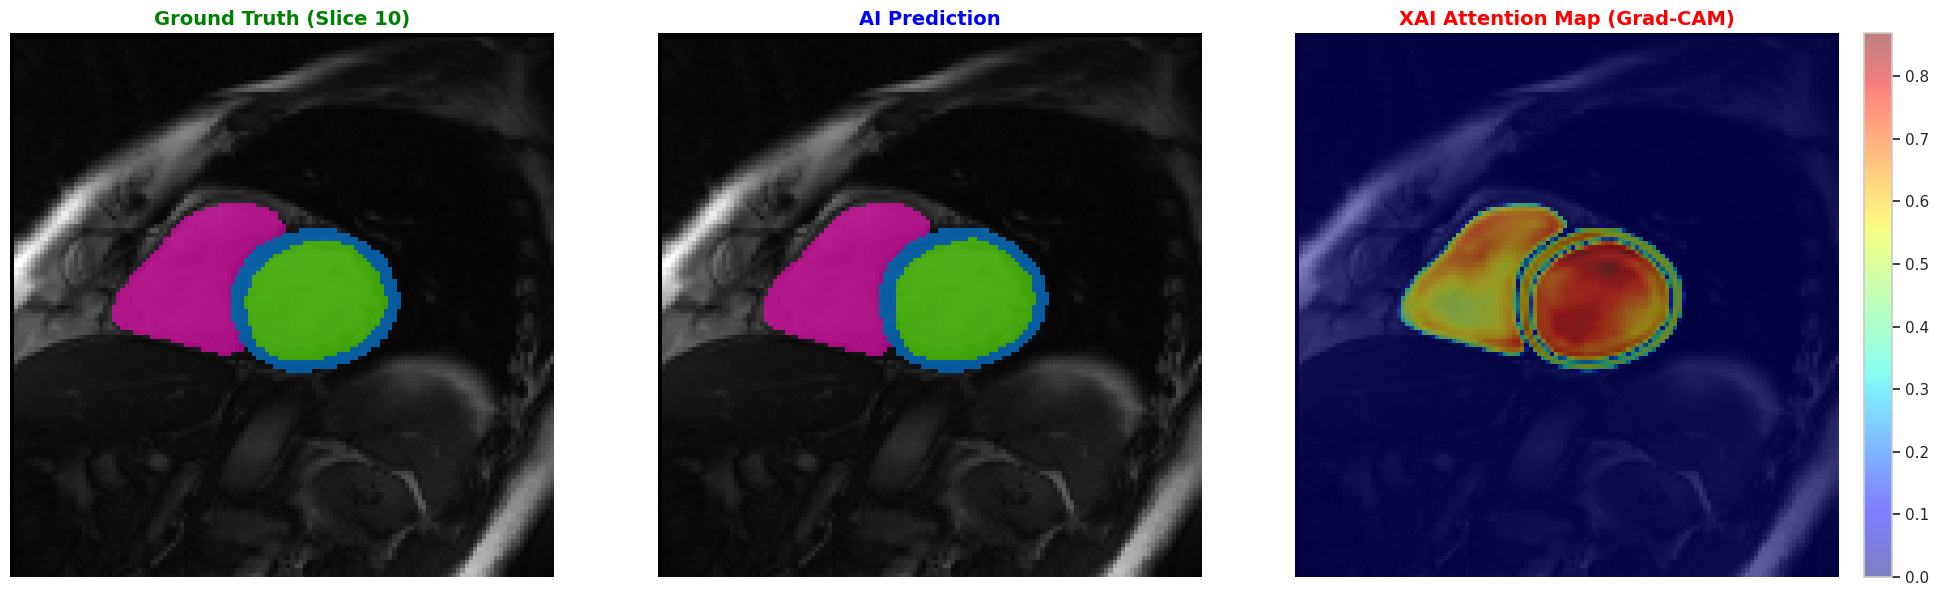


>> Đang phân tích mẫu ID: 97


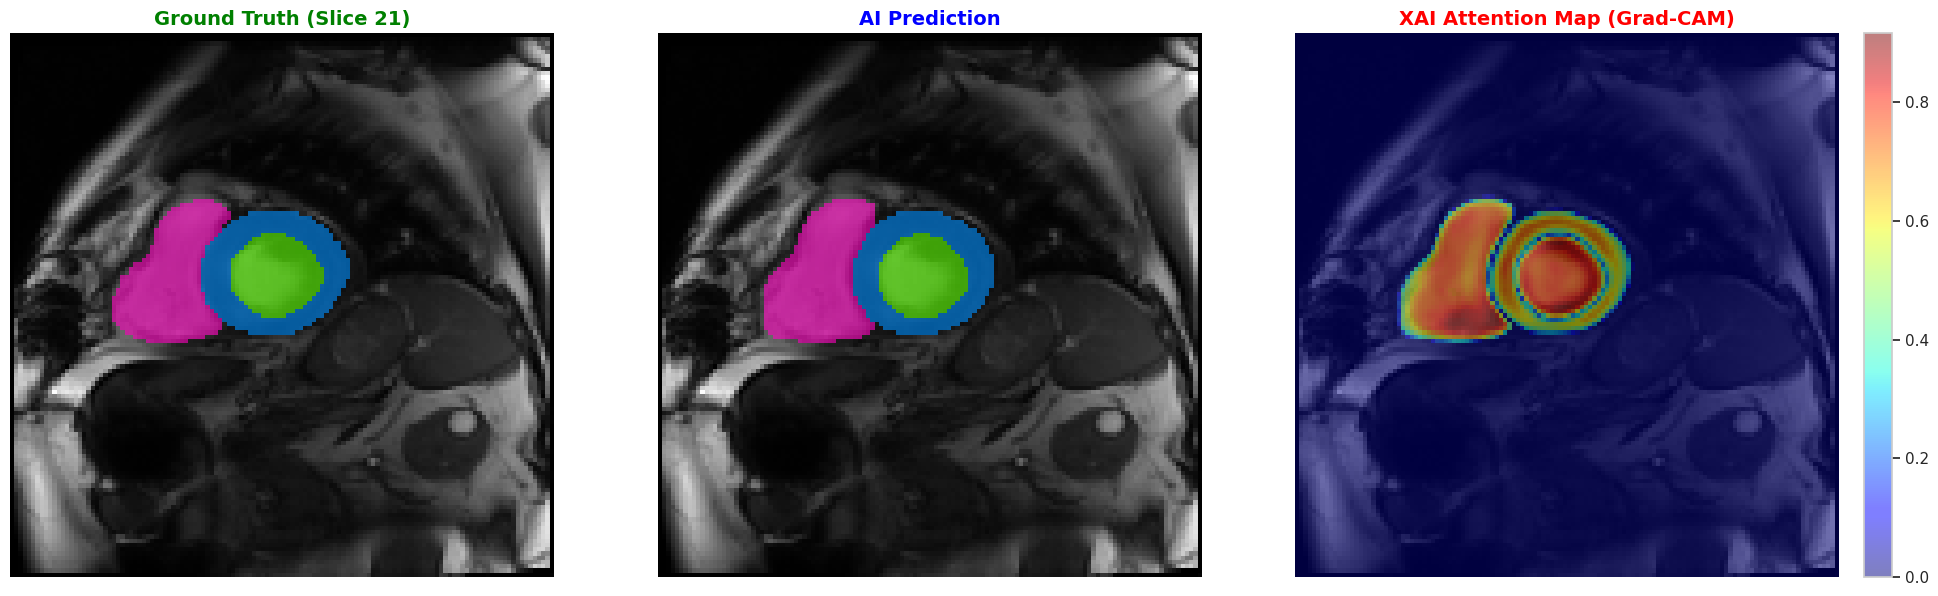


>> Đang phân tích mẫu ID: 43


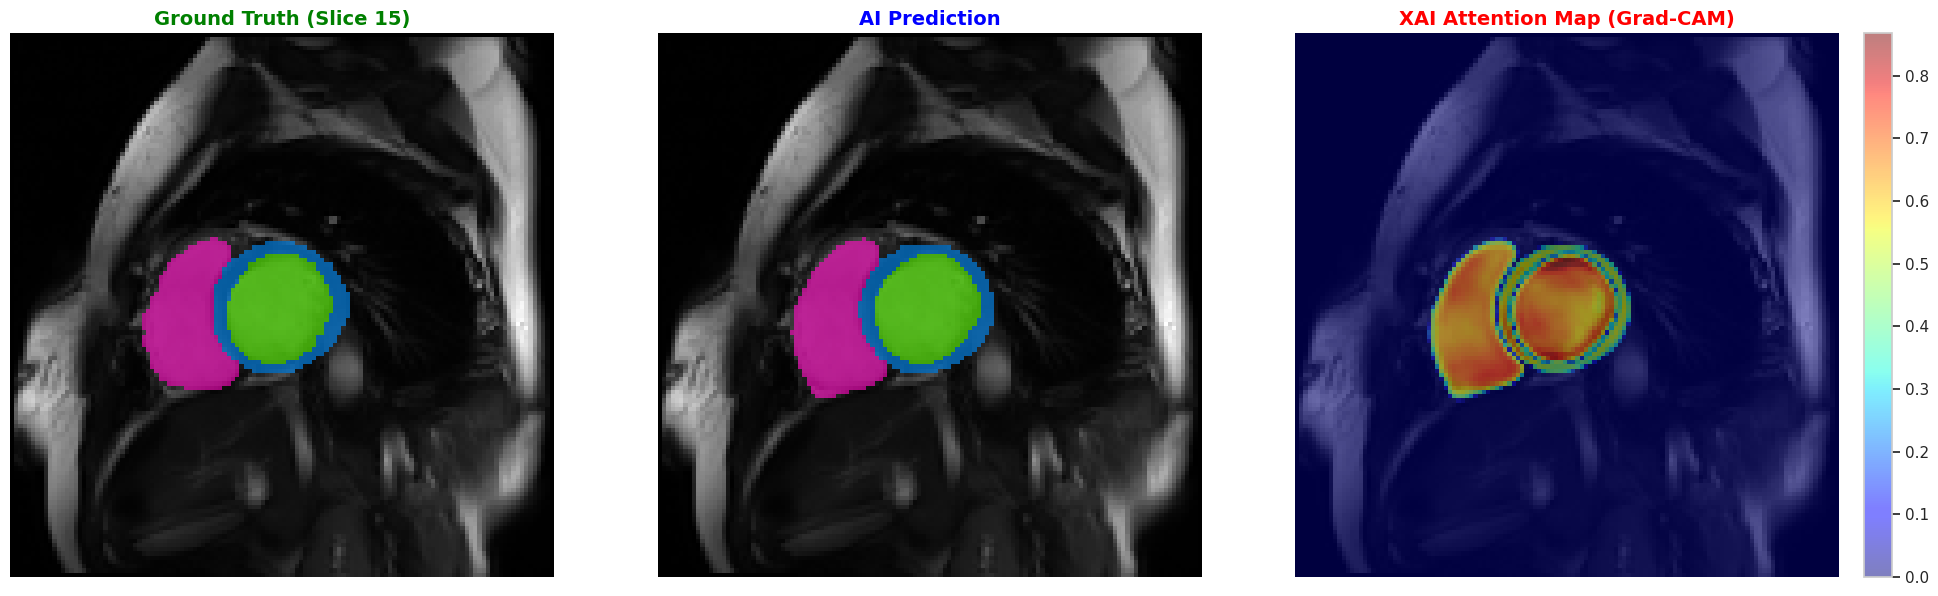


>> Đang phân tích mẫu ID: 13


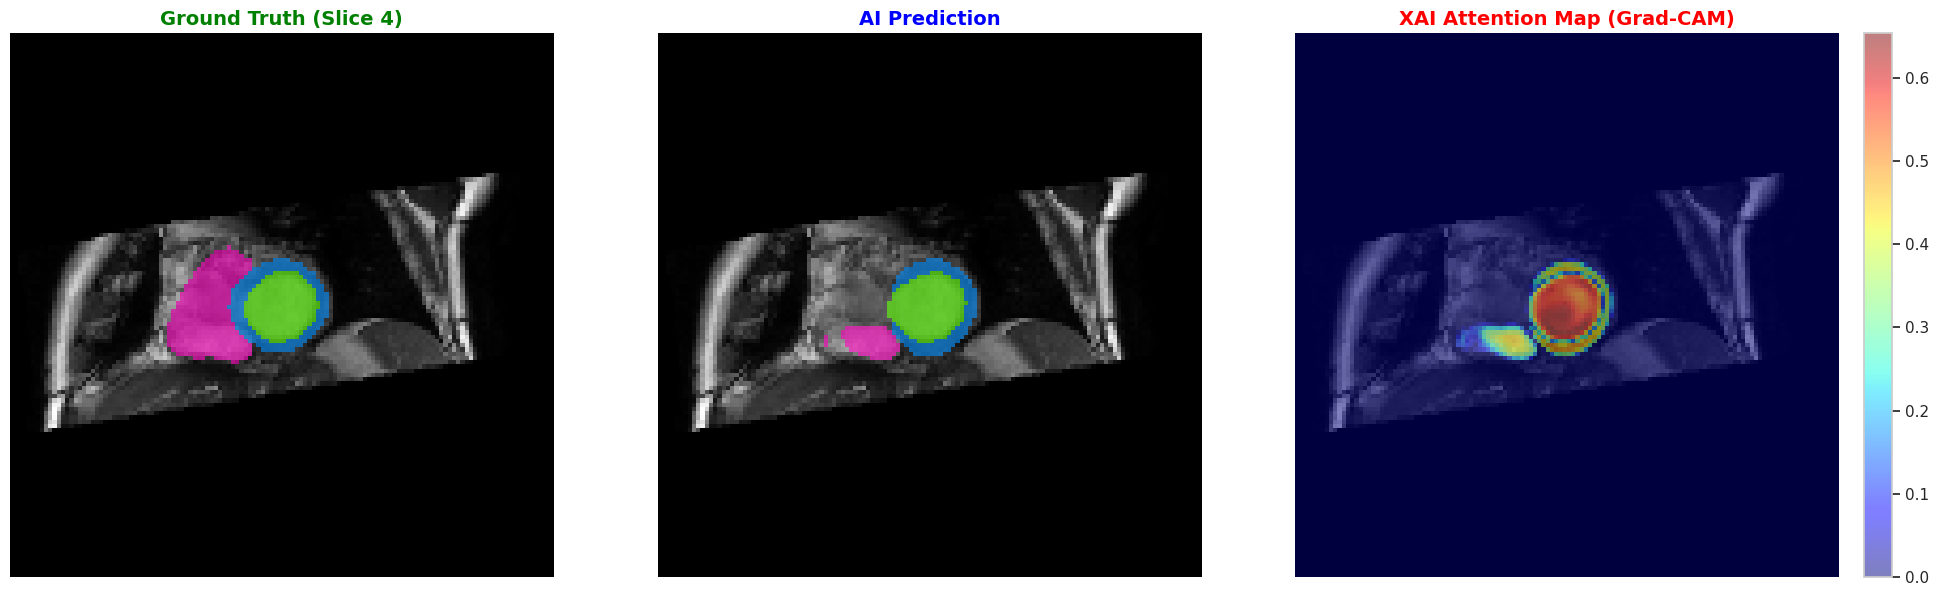


>> Đang phân tích mẫu ID: 11


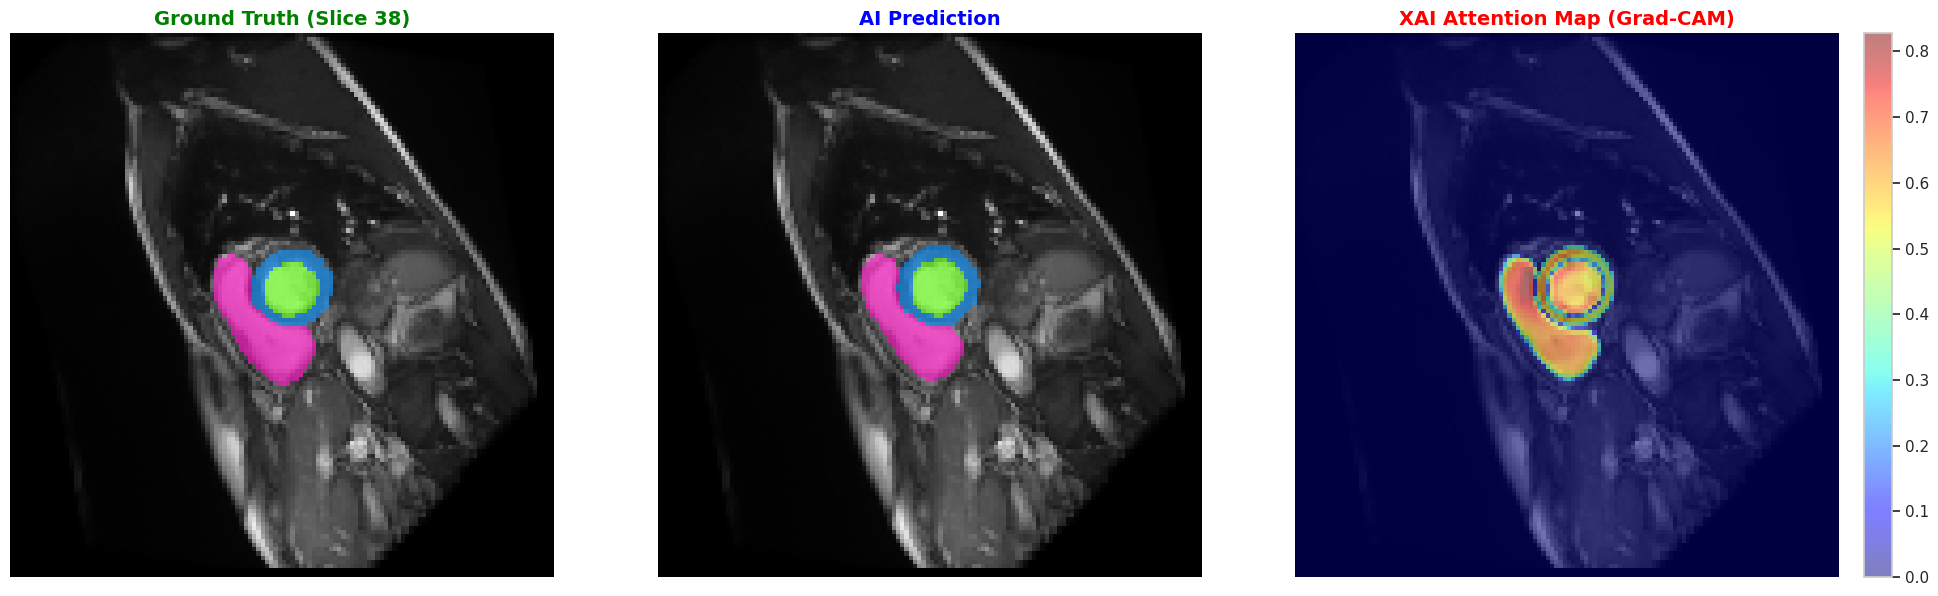


>> Đang phân tích mẫu ID: 48


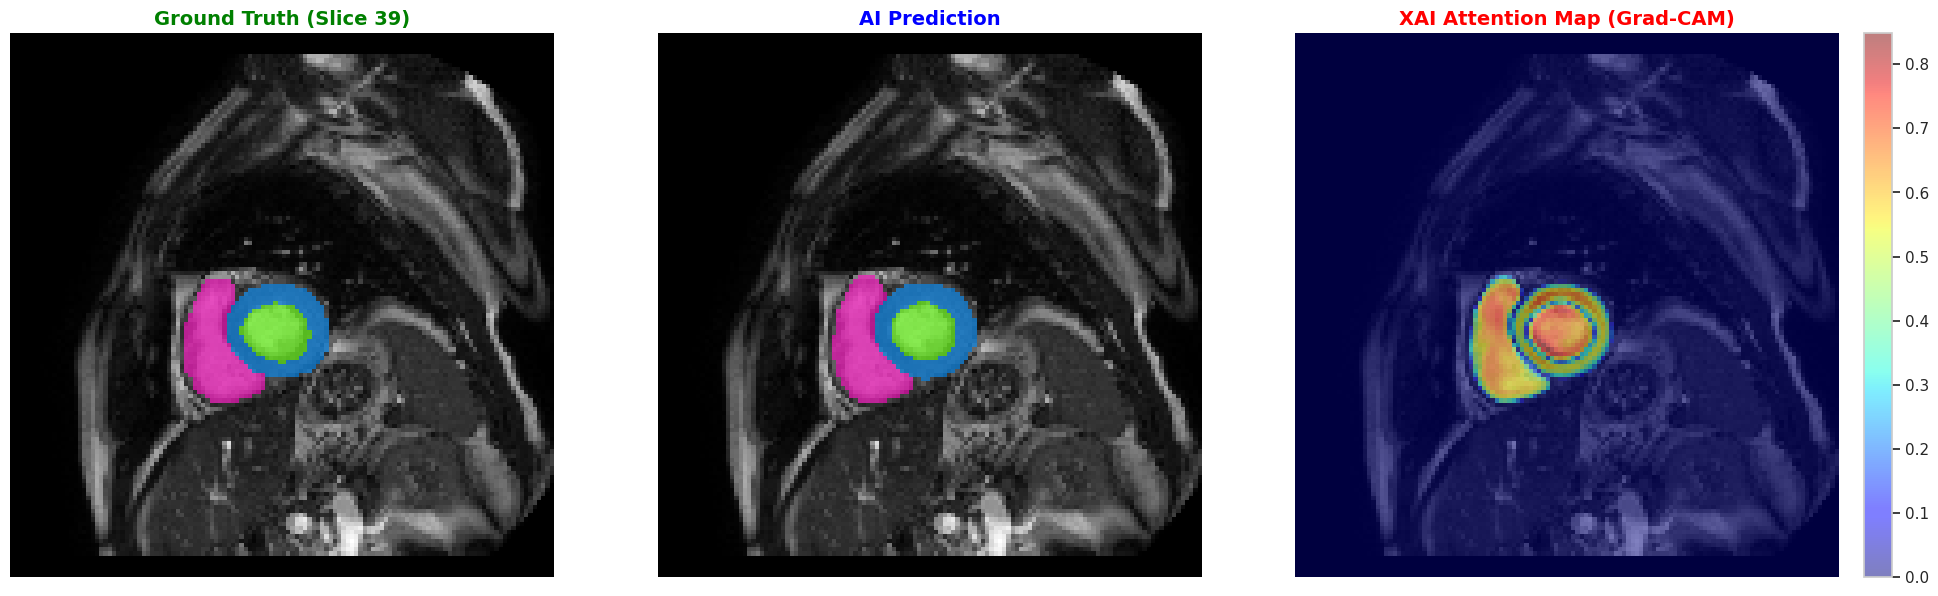

✅ Hoàn tất Visualization.


In [45]:
# ==============================================================================
# 2. DASHBOARD VISUALIZATION FUNCTION
# ==============================================================================
def visualize_xai_prediction_dashboard(model, items, device="cuda", num_samples=6):
    """
    Hàm tổng hợp: Chạy dự đoán + Tính Grad-CAM + Vẽ Dashboard 3 cột
    """
    print(f"🚀 Đang khởi tạo XAI Dashboard cho {num_samples} mẫu...")
    
    model.eval()
    
    # --- A. TỰ ĐỘNG TÌM TARGET LAYER ---
    # Tìm layer Conv3D cuối cùng (nơi chứa đặc trưng không gian sâu nhất)
    conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
    if not conv_layers:
        print("Lỗi: Không tìm thấy layer Conv3D nào trong model!")
        return
    target_layer = conv_layers[-1]
    print(f"🎯 Target Layer: {target_layer}")

    # Khởi tạo công cụ Grad-CAM
    cam_extractor = GradCAM3D(model, target_layer)
    
    # Load dataset test
    # Lưu ý: Class VolumeDataset phải đã được định nghĩa ở cell trước
    dataset = VolumeDataset(items) 
    
    # Chọn mẫu ngẫu nhiên
    sample_indices = random.sample(range(len(items)), min(len(items), num_samples))

    # --- B. VÒNG LẶP XỬ LÝ TỪNG MẪU ---
    for idx in sample_indices:
        try:
            print(f"\n>> Đang phân tích mẫu ID: {idx}")
            data = dataset[idx]
            
            # Input cần require grad để tính ngược
            img = data['image'].unsqueeze(0).to(device)
            img.requires_grad = True 
            
            label = data['label'].numpy() # (128, 128, 64)
            
            # 1. Chạy dự đoán (Prediction)
            out = model(img)
            pred = torch.argmax(out, 1).detach().cpu().numpy()[0]

            # 2. Tính Grad-CAM tổng hợp (Gộp Heatmap của LV, MYO, RV)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Duyệt qua 3 lớp tim: 1(LV), 2(MYO), 3(RV)
            for c in [1, 2, 3]: 
                try:
                    # Tạo heatmap thô (kích thước nhỏ)
                    h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                    
                    # Tính tỷ lệ phóng to để khớp với ảnh gốc
                    zoom_factor = (
                        label.shape[0] / h_small.shape[0],
                        label.shape[1] / h_small.shape[1],
                        label.shape[2] / h_small.shape[2]
                    )
                    
                    # Phóng to heatmap (Zoom)
                    h_large = zoom(h_small, zoom_factor, order=1)
                    
                    # Cộng dồn vào bản đồ nhiệt tổng (Lấy max để giữ điểm nóng nhất)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except Exception as e:
                    # Bỏ qua nếu class này không xuất hiện hoặc lỗi gradient
                    continue

            # 3. Chọn lát cắt (Slice) hiển thị
            img_np = img.detach().cpu().numpy()[0, 0]
            
            # Tìm lát cắt có diện tích tim lớn nhất
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else 32

            # --- C. VẼ ĐỒ THỊ ---
            plt.figure(figsize=(20, 6))
            
            # Ô 1: Ground Truth
            plt.subplot(1, 3, 1)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Masked array để ẩn phần nền (class 0)
            gt_masked = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
            plt.imshow(gt_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title(f"Ground Truth (Slice {slice_idx})", fontsize=14, color='green', fontweight='bold')
            plt.axis('off')

            # Ô 2: Prediction
            plt.subplot(1, 3, 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            pred_masked = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
            plt.imshow(pred_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title(f"AI Prediction", fontsize=14, color='blue', fontweight='bold')
            plt.axis('off')

            # Ô 3: XAI Attention Map (Grad-CAM) 
            plt.subplot(1, 3, 3)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Hiển thị Heatmap đè lên ảnh gốc
            im = plt.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            plt.title(f"XAI Attention Map (Grad-CAM)", fontsize=14, color='red', fontweight='bold')
            plt.axis('off')
            plt.colorbar(im, fraction=0.046, pad=0.04)

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"Lỗi khi xử lý mẫu {idx}: {e}")
            continue

    # Dọn dẹp Hook cuối cùng
    cam_extractor.remove_hooks()
    print("✅ Hoàn tất Visualization.")

# ==============================================================================
# 3. RUN (GỌI HÀM)
# ==============================================================================
# Đảm bảo bạn đã có biến 'model', 'te_items' (tập test), và 'DEVICE' từ các bước trước
visualize_xai_prediction_dashboard(model, te_items, device=DEVICE, num_samples=6)

# **GradCAM trên từng tầng mạng**

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


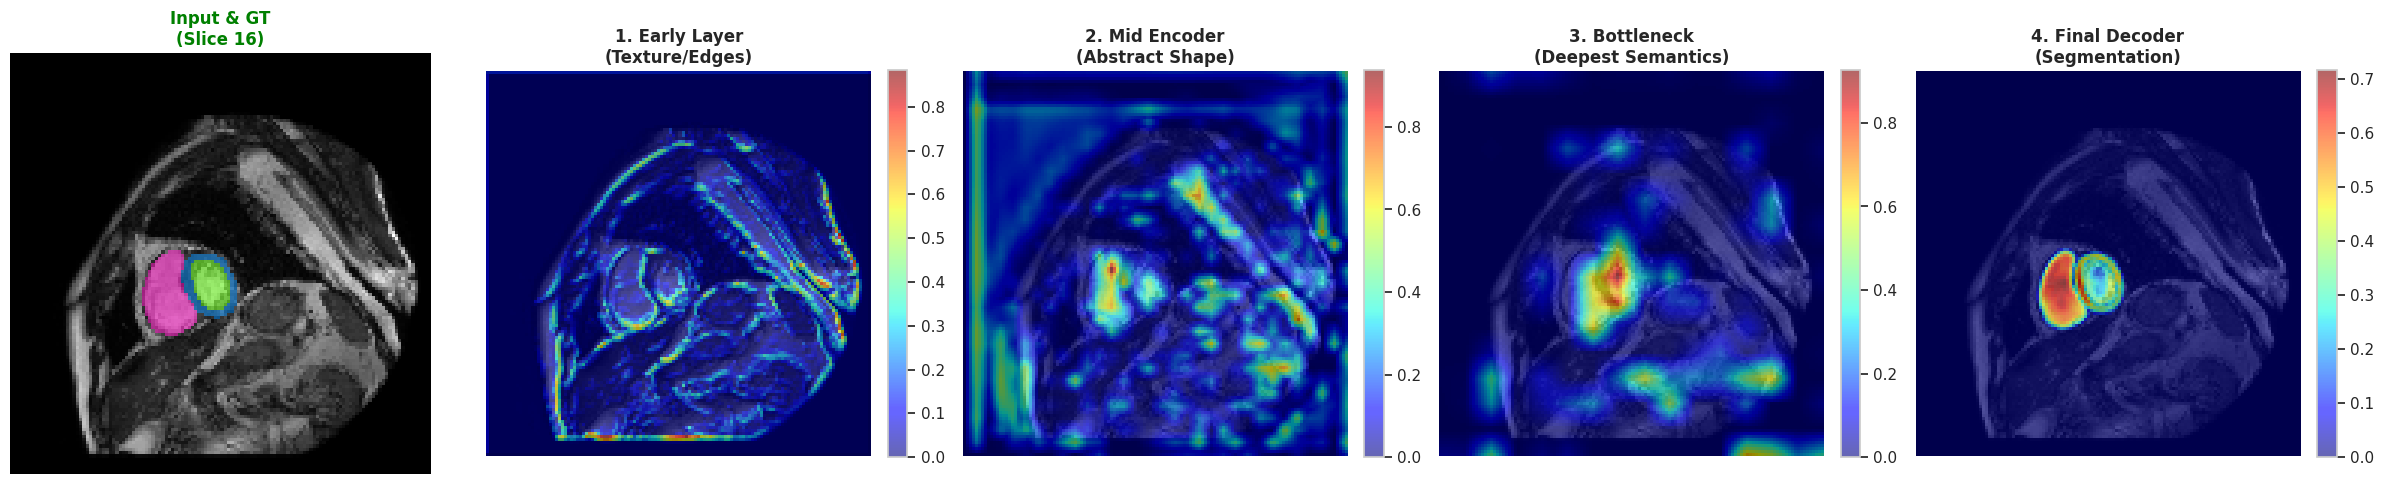

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


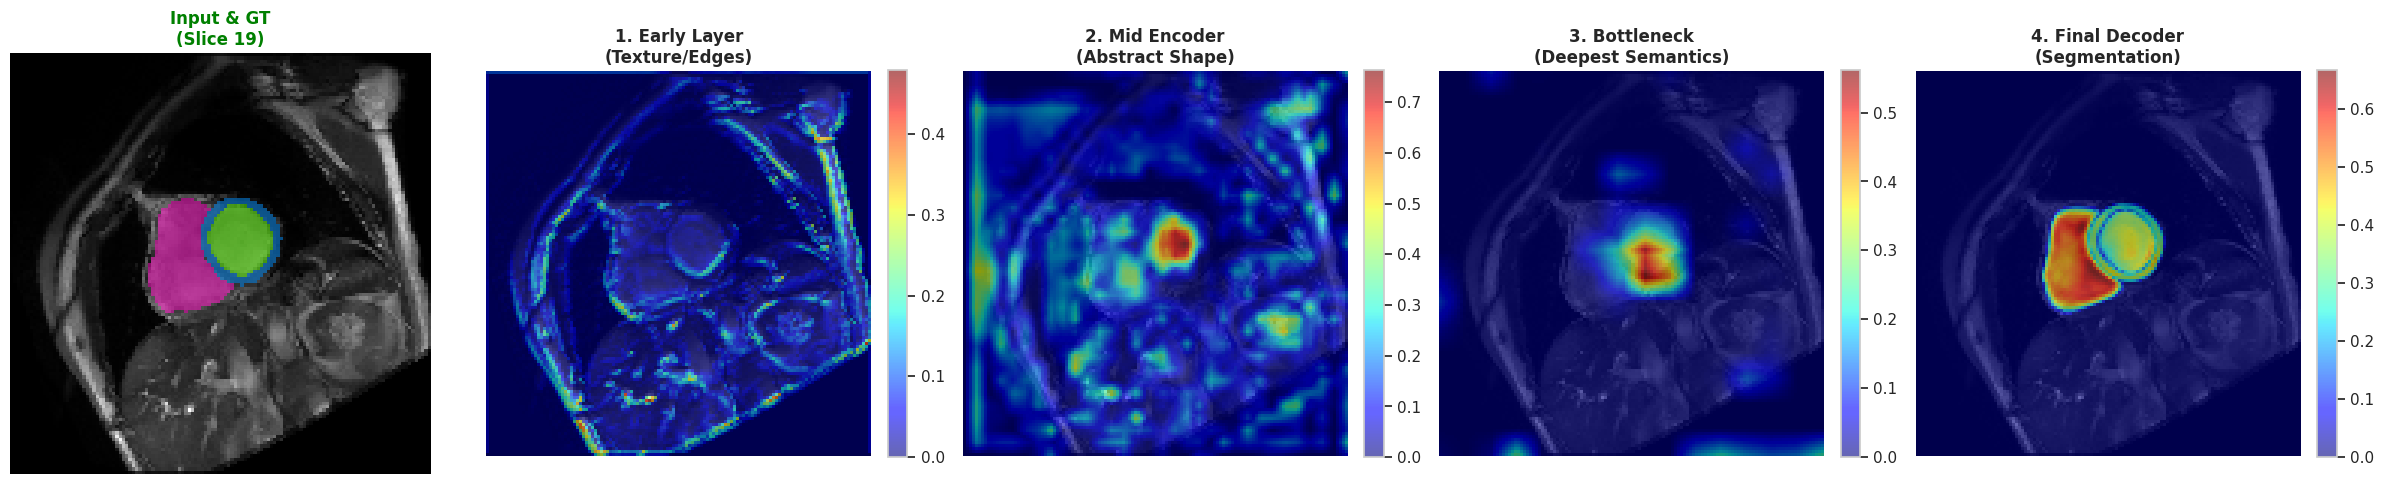

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


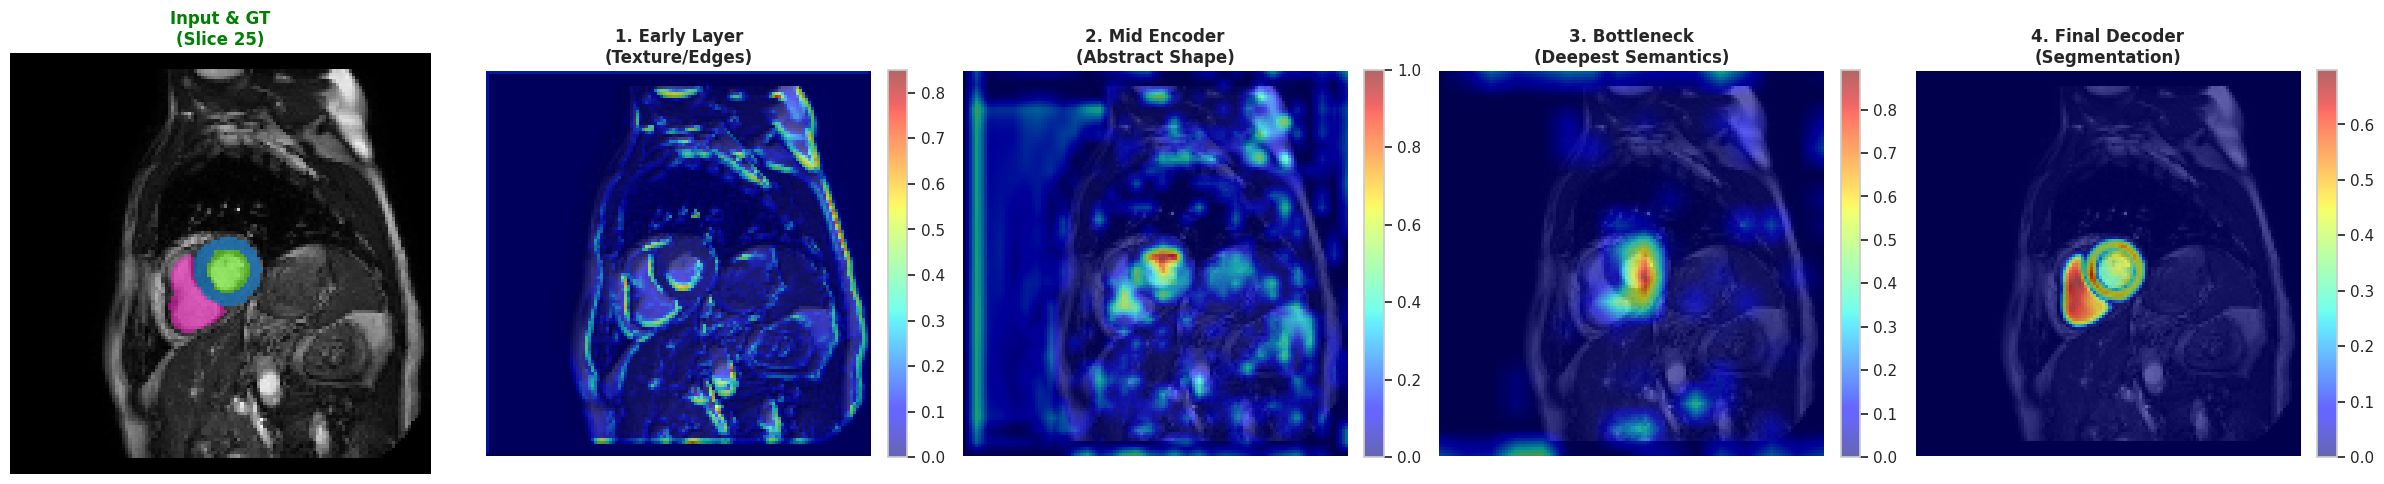

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
from scipy.ndimage import zoom

def visualize_layer_evolution(model, items, device="cuda", sample_idx=None):
    """
    Trực quan hóa sự tiến hóa của vùng chú ý (Attention) qua các tầng mạng.
    (ĐÃ SỬA LỖI attribute convFinal)
    """
    print("🚀 Đang khởi tạo Layer-wise Visualization...")
    model.eval()
    
    # --- [SỬA LỖI TẠI ĐÂY] ---
    # Thay thế model.convFinal bằng model.up_layers[-1]
    target_layers = {
        "1. Early Layer\n(Texture/Edges)": model.convInit,
        "2. Mid Encoder\n(Abstract Shape)": model.down_layers[2], 
        "3. Bottleneck\n(Deepest Semantics)": model.down_layers[3],
        "4. Final Decoder\n(Segmentation)": model.up_layers[-1] # Sửa thành lớp upsample cuối cùng
    }

    # Chọn mẫu
    if sample_idx is None:
        sample_idx = random.randint(0, len(items)-1)
    
    ds = VolumeDataset([items[sample_idx]])
    data = ds[0]
    img = data['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = data['label'].numpy()
    
    # Lấy ảnh gốc để hiển thị
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tìm slice đẹp nhất
    sums = np.sum(label > 0, axis=(0, 1))
    slice_idx = np.argmax(sums) if np.max(sums) > 0 else 32

    # --- KHỞI TẠO PLOT ---
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(24, 5))
    
    # Cột 1: Ảnh gốc + Ground Truth
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    axes[0].set_title(f"Input & GT\n(Slice {slice_idx})", fontweight='bold', color='green')
    axes[0].axis('off')

    # --- DUYỆT QUA CÁC TẦNG ---
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        print(f"  >> Đang phân tích tầng: {layer_name.replace(chr(10), ' ')}...")
        
        # Khởi tạo GradCAM cho tầng hiện tại
        cam_extractor = GradCAM3D(model, layer_module)
        
        # Tính Heatmap tổng hợp (LV + MYO + RV)
        combined_heatmap = np.zeros_like(label, dtype=np.float32)
        
        for c in [1, 2, 3]: 
            try:
                # Generate CAM
                h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                
                # Zoom lên kích thước gốc
                zoom_factor = (
                    label.shape[0] / h_small.shape[0],
                    label.shape[1] / h_small.shape[1],
                    label.shape[2] / h_small.shape[2]
                )
                h_large = zoom(h_small, zoom_factor, order=1)
                combined_heatmap = np.maximum(combined_heatmap, h_large)
            except:
                continue
        
        # Gỡ hook
        cam_extractor.remove_hooks()

        # Hiển thị
        ax = axes[i + 1]
        ax.imshow(img_np[:, :, slice_idx], cmap='gray')
        
        # Normalize để hiển thị đẹp hơn
        if combined_heatmap.max() > 0:
            combined_heatmap /= combined_heatmap.max()
            
        im = ax.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.6)
        ax.set_title(layer_name, fontweight='bold')
        ax.axis('off')
        
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- CHẠY THỬ ---
for _ in range(3):
    visualize_layer_evolution(model, te_items, device=DEVICE)

🚀 Đang chọn ngẫu nhiên 3 bệnh nhân để soi toàn bộ mạng...

Example #1 (Index: 54)


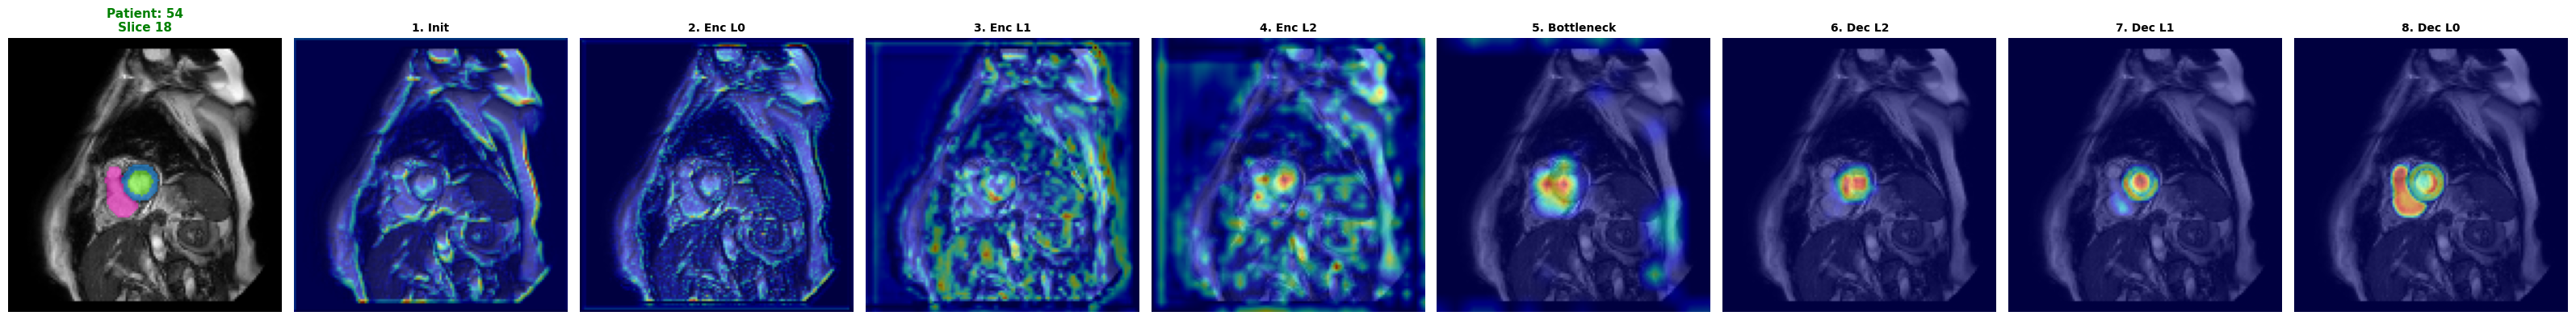


Example #2 (Index: 4)


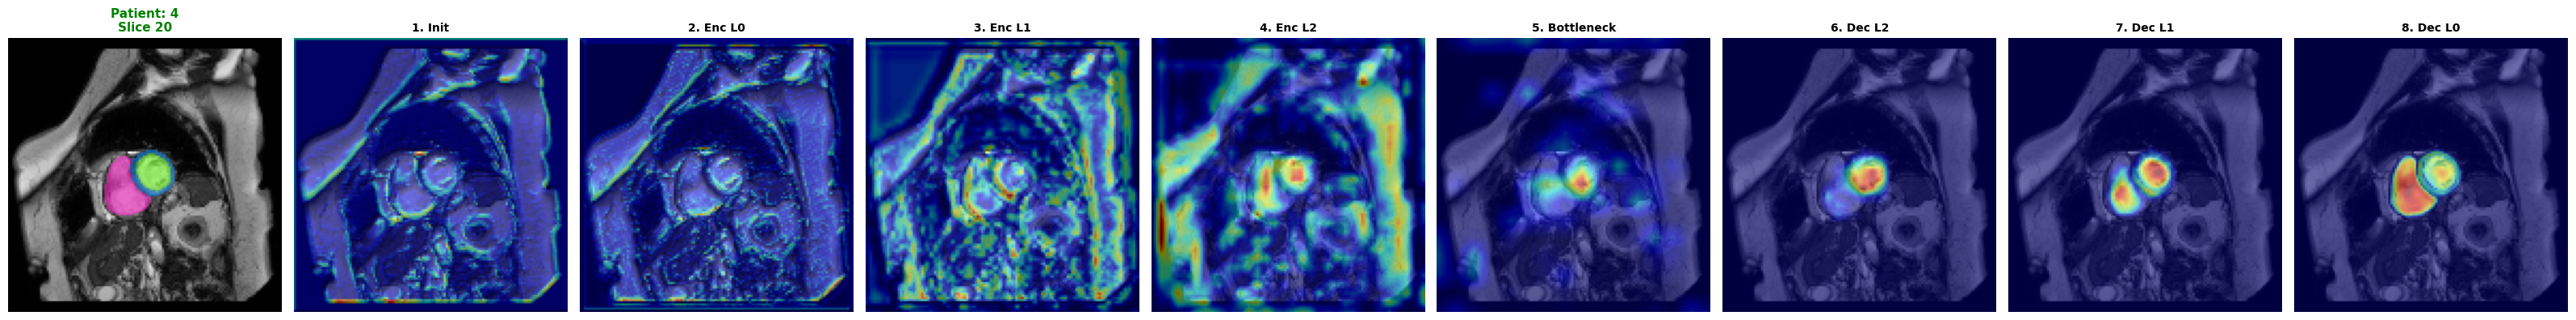


Example #3 (Index: 3)


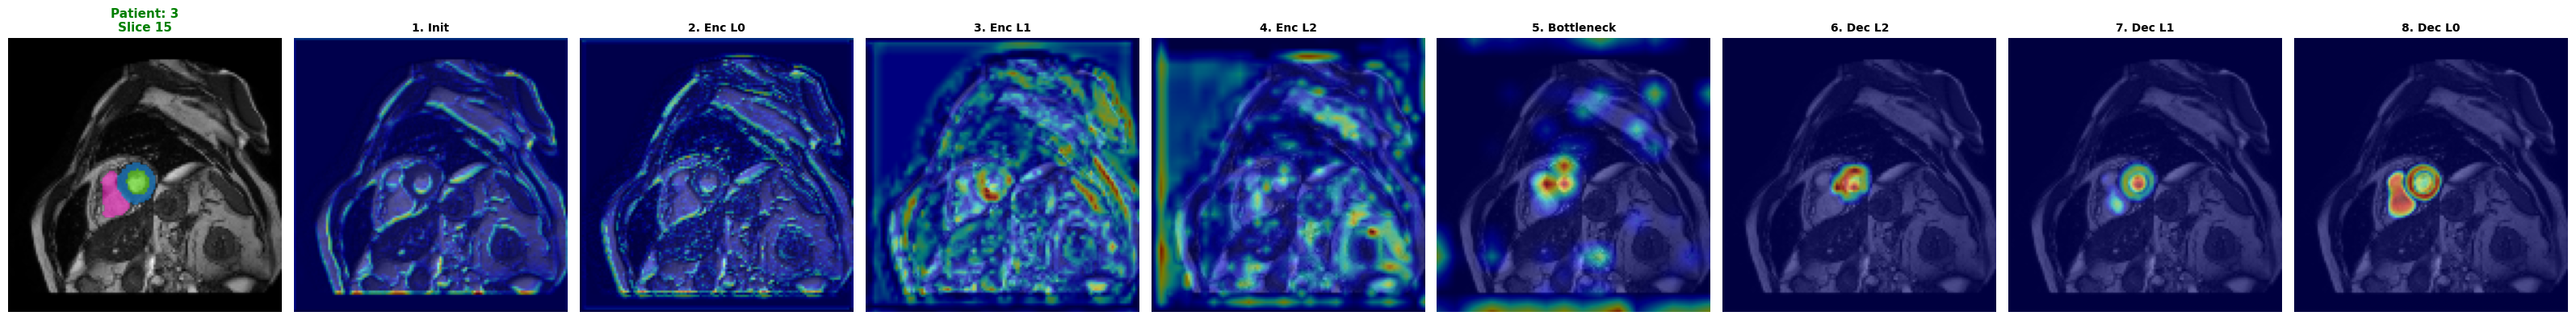

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import random
import os
from scipy.ndimage import zoom

# ==============================================================================
# 1. CLASS GRAD-CAM (Giữ nguyên)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        if self.gradients is None or self.activations is None: return None
            
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

    def remove_hooks(self):
        for h in self.handles: h.remove()

# ==============================================================================
# 2. HÀM VẼ 1 BỆNH NHÂN (Đã tối ưu)
# ==============================================================================
def visualize_single_patient(model, item, device, patient_idx):
    # Định nghĩa các tầng
    target_layers = {
        "1. Init":         model.convInit,
        "2. Enc L0":       model.down_layers[0],
        "3. Enc L1":       model.down_layers[1],
        "4. Enc L2":       model.down_layers[2],
        "5. Bottleneck":   model.down_layers[3],
        "6. Dec L2":       model.up_layers[0],
        "7. Dec L1":       model.up_layers[1],
        "8. Dec L0":       model.up_layers[2]
    }

    # Prepare Data
    ds = VolumeDataset([item])
    img = ds[0]['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = ds[0]['label'].numpy()
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tìm slice đẹp nhất
    sums = np.sum(label > 0, axis=(0, 1))
    slice_idx = np.argmax(sums) if np.max(sums) > 0 else img_np.shape[2] // 2

    # Setup Plot (1 hàng, 9 cột)
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(32, 4))
    
    # Cột 1: Input + GT
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    
    # Lấy tên file cho đẹp
    fname = item['image'].split('/')[-1] if isinstance(item, dict) else str(patient_idx)
    axes[0].set_title(f"Patient: {fname}\nSlice {slice_idx}", fontweight='bold', color='green', fontsize=11)
    axes[0].axis('off')

    # Vẽ các tầng
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        try:
            cam_extractor = GradCAM3D(model, layer_module)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Quét 3 lớp tim
            for c in [1, 2, 3]: 
                try:
                    h = cam_extractor.generate_heatmap(img, class_idx=c)
                    if h is None: continue
                    z_factor = (label.shape[0]/h.shape[0], label.shape[1]/h.shape[1], label.shape[2]/h.shape[2])
                    h_large = zoom(h, z_factor, order=1)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except: continue
            
            cam_extractor.remove_hooks()

            ax = axes[i + 1]
            ax.imshow(img_np[:, :, slice_idx], cmap='gray')
            if combined_heatmap.max() > 0: combined_heatmap /= combined_heatmap.max()
            ax.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            ax.set_title(layer_name, fontweight='bold', fontsize=10)
            ax.axis('off')
        except: continue

    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. HÀM CHẠY 3 BỆNH NHÂN (Wrapper)
# ==============================================================================
def run_3_patients_demo(model, items, device="cuda"):
    print("🚀 Đang chọn ngẫu nhiên 3 bệnh nhân để soi toàn bộ mạng...")
    model.eval()
    
    # Lấy 3 chỉ số ngẫu nhiên không trùng nhau
    # Nếu dataset < 3 mẫu thì lấy hết
    count = min(3, len(items))
    indices = random.sample(range(len(items)), count)
    
    for i, idx in enumerate(indices):
        print(f"\nExample #{i+1} (Index: {idx})")
        visualize_single_patient(model, items[idx], device, idx)

# --- THỰC THI ---
# 1. Đảm bảo load trọng số tốt nhất trước
# model = load_best_weights(model, "path/to/best_model.pth") 

# 2. Chạy
run_3_patients_demo(model, te_items, device=DEVICE)

# **Độ bất định**

🚀 Đang tính toán Uncertainty Map (MC Dropout) cho 3 mẫu...


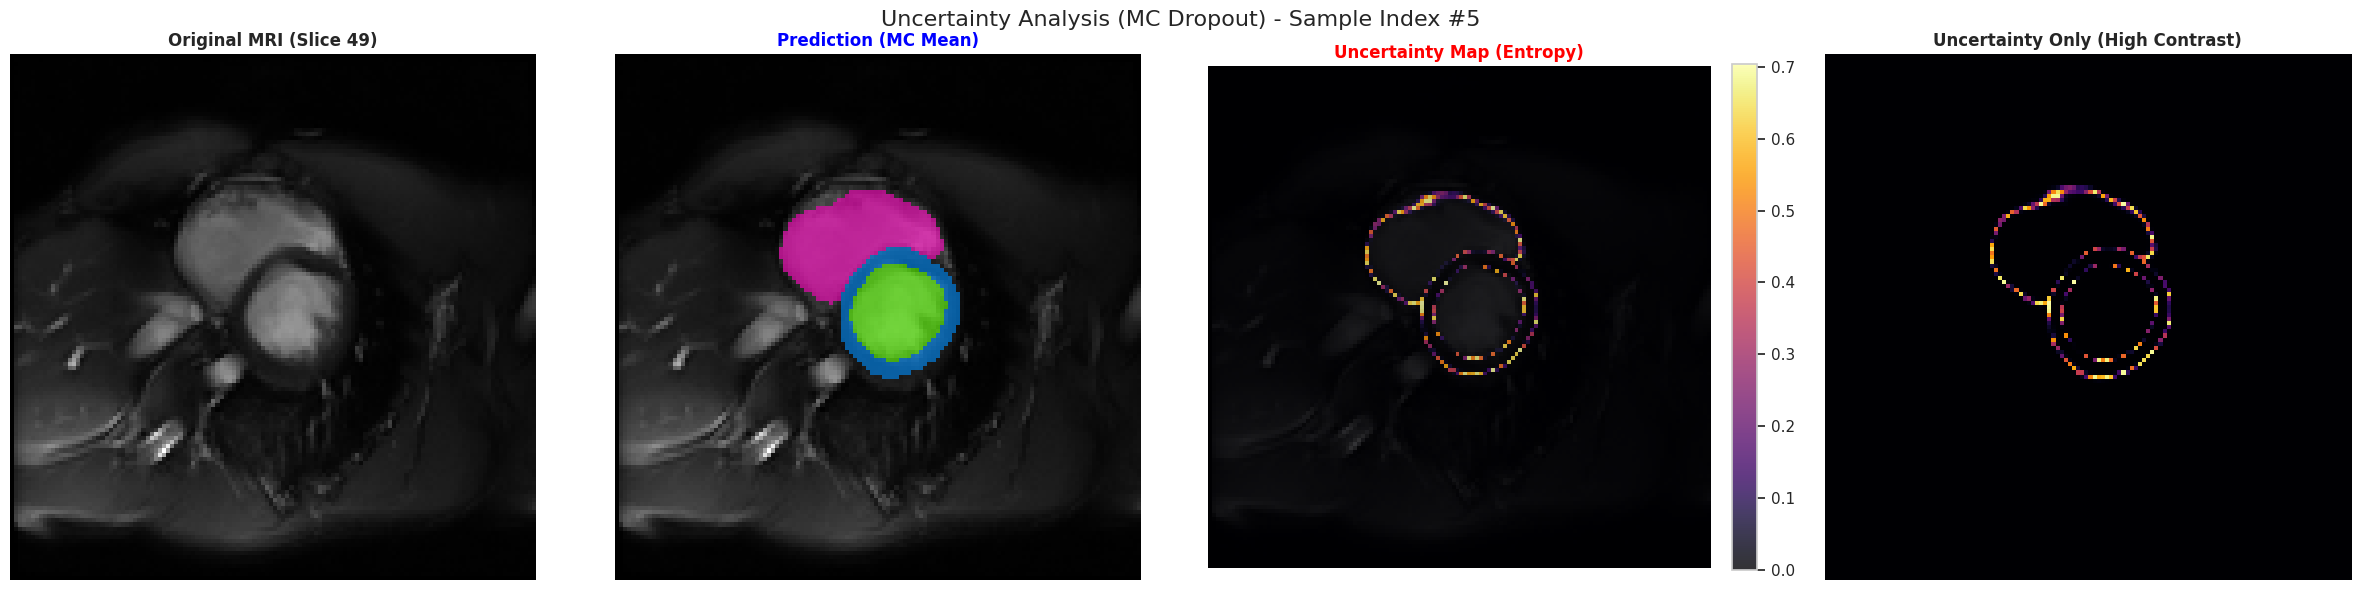

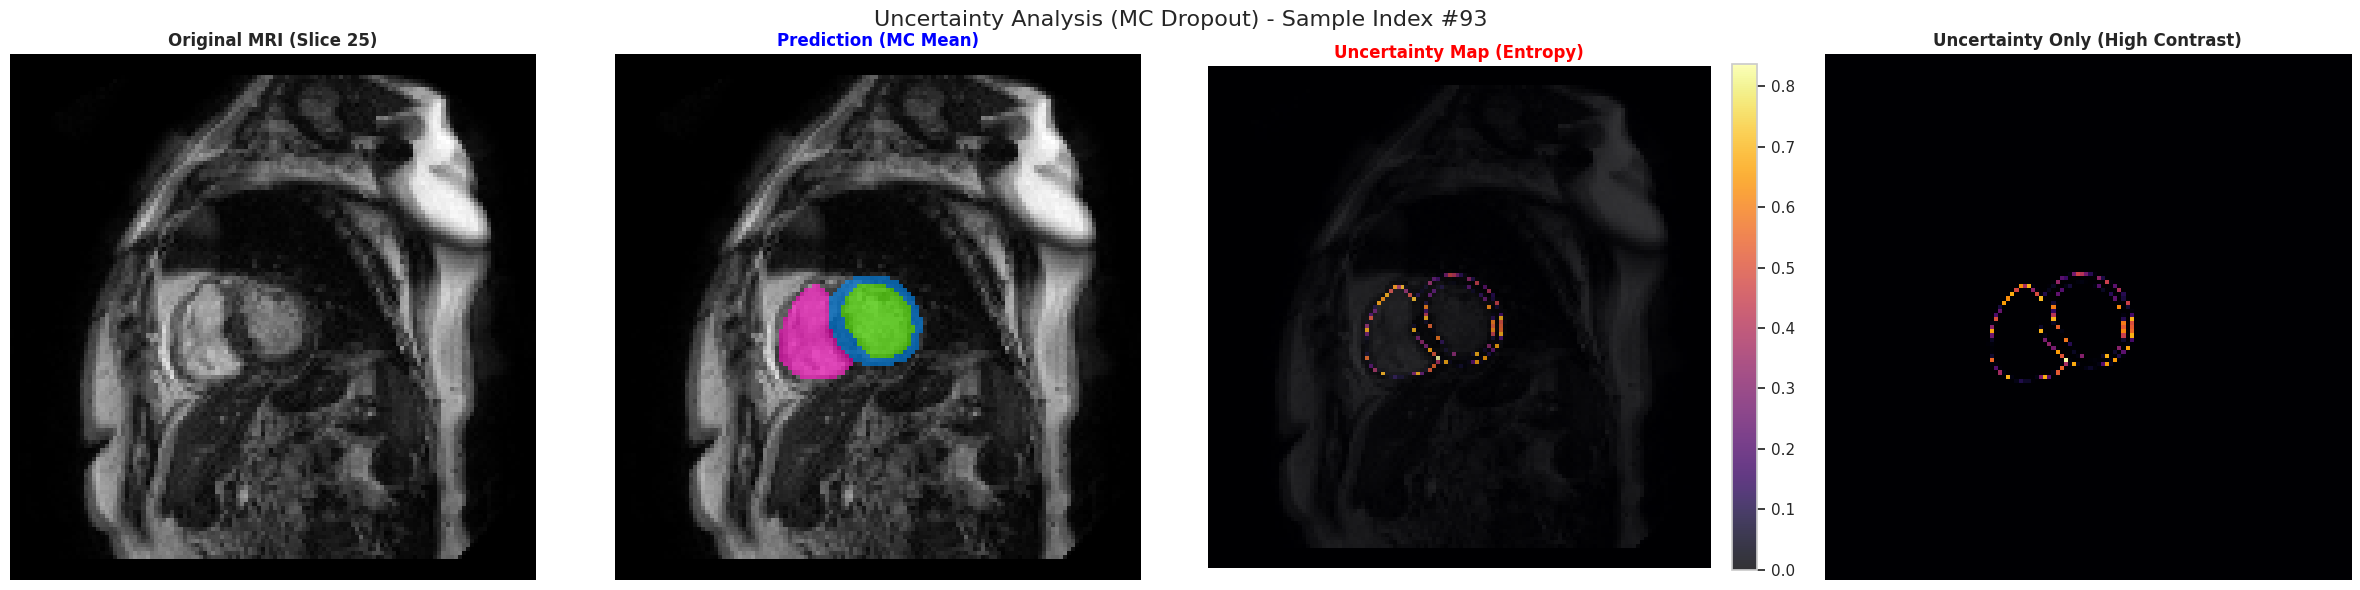

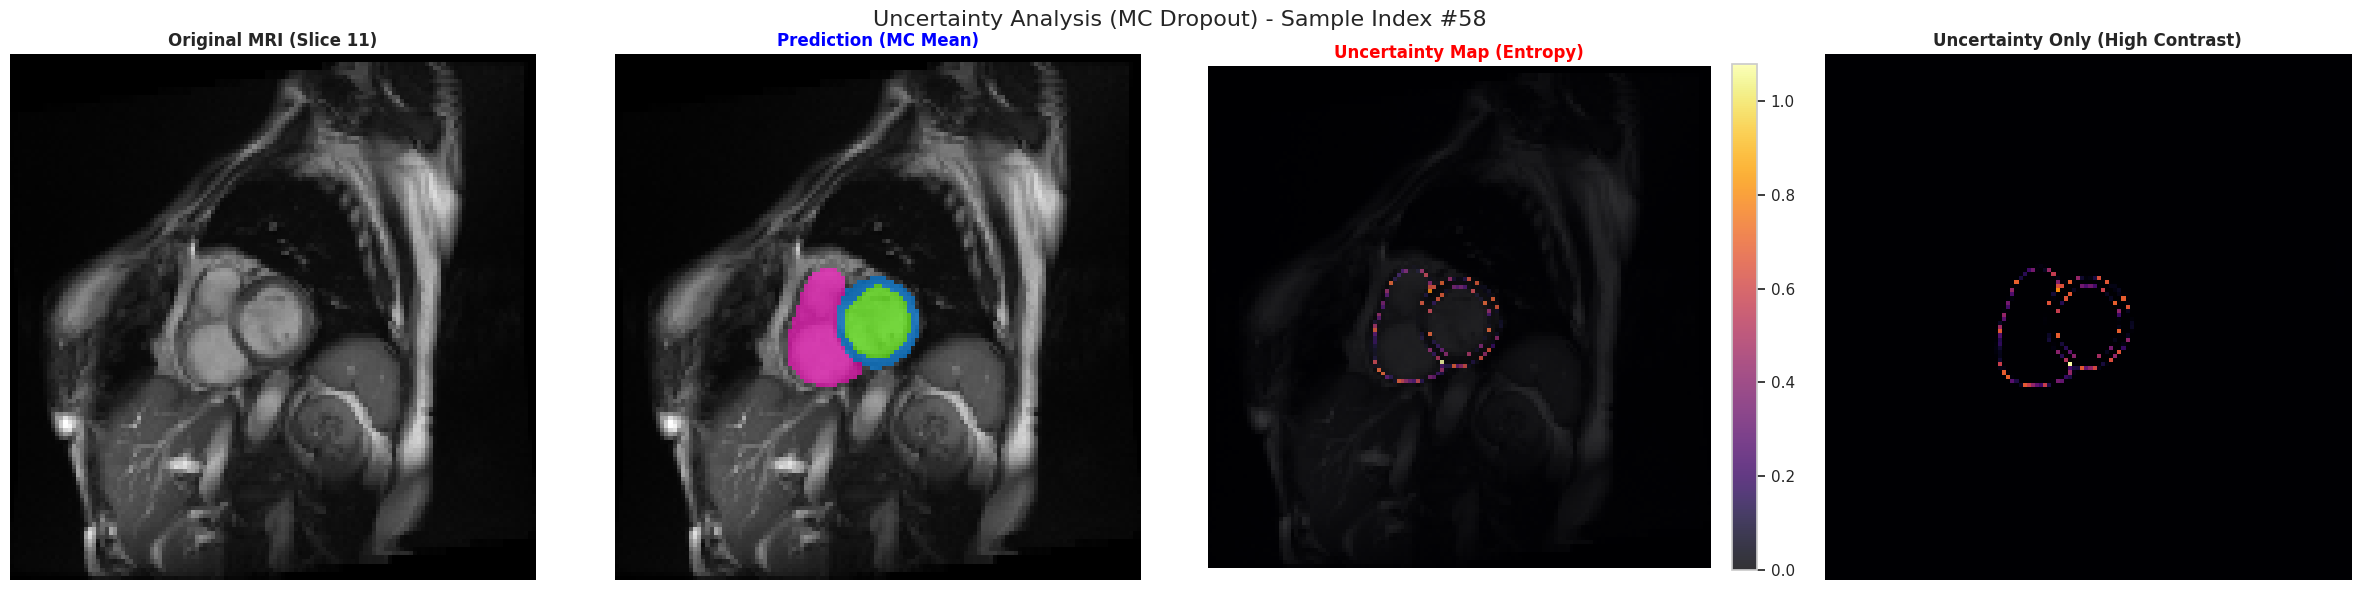

In [49]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random

# ==============================================================================
# 1. HÀM TÍNH ĐỘ BẤT ĐỊNH (UNCERTAINTY)
# ==============================================================================
def compute_uncertainty_mc_dropout(model, input_tensor, T=15):
    """
    Thực hiện Monte Carlo Dropout để ước lượng độ bất định.
    Input:
        - model: Mô hình SegResNet
        - input_tensor: Ảnh đầu vào (1, 1, D, H, W)
        - T: Số lần chạy lặp lại (sampling). T càng cao bản đồ càng mượt (thường 10-20).
    Output:
        - mean_pred: Kết quả dự đoán trung bình (Softmax)
        - uncertainty_map: Bản đồ Entropy (Độ bất định)
    """
    # [QUAN TRỌNG] Kích hoạt chế độ Train để bật Dropout
    model.train() 
    
    outputs = []
    
    with torch.no_grad():
        for _ in range(T):
            # Forward pass
            logits = model(input_tensor)
            # Chuyển về xác suất (Probability)
            probs = torch.softmax(logits, dim=1)
            outputs.append(probs) # List các tensor (1, C, D, H, W)
            
    # Xếp chồng kết quả: (T, 1, C, D, H, W)
    outputs = torch.stack(outputs)
    
    # 1. Tính Mean Probability (Dự đoán trung bình của T lần chạy)
    mean_prob = torch.mean(outputs, dim=0) # (1, C, D, H, W)
    
    # 2. Tính Predictive Entropy (Độ bất định)
    # Công thức Shannon Entropy: H = - sum( p * log(p) )
    epsilon = 1e-6 # Tránh lỗi log(0)
    uncertainty_map = -torch.sum(mean_prob * torch.log(mean_prob + epsilon), dim=1)
    
    # [QUAN TRỌNG] Trả model về chế độ Eval để không ảnh hưởng các đoạn code khác
    model.eval()
    
    return mean_prob, uncertainty_map

# ==============================================================================
# 2. VISUALIZATION DASHBOARD
# ==============================================================================
def visualize_uncertainty_xai(model, items, device="cuda", num_samples=3):
    print(f"🚀 Đang tính toán Uncertainty Map (MC Dropout) cho {num_samples} mẫu...")
    
    # Load lại weight tốt nhất nếu cần thiết
    chk_path = SAVE_DIR / "best_model.pth"
    if not chk_path.exists():
         chk_path = Path("/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth")
    if chk_path.exists():
        model.load_state_dict(torch.load(chk_path, map_location=device))
    
    # Chọn mẫu ngẫu nhiên từ tập Test (te_items)
    # Lưu ý: te_items phải được định nghĩa từ các bước trước
    indices = random.sample(range(len(items)), min(len(items), num_samples))
    ds = VolumeDataset([items[i] for i in indices])

    for i in range(len(ds)):
        sample = ds[i]
        img = sample["image"].unsqueeze(0).to(device) # (1, 1, D, H, W)
        label = sample["label"].numpy()
        
        # --- TÍNH UNCERTAINTY ---
        # Chạy MC Dropout 15 lần
        mean_prob, unc_map = compute_uncertainty_mc_dropout(model, img, T=15)
        
        # Lấy nhãn dự đoán từ mean_prob
        pred_mask = torch.argmax(mean_prob, dim=1).detach().cpu().numpy()[0]
        unc_map_np = unc_map.detach().cpu().numpy()[0] # (D, H, W)
        
        # --- TÌM SLICE ĐẸP NHẤT ---
        # Tìm lát cắt có diện tích tim lớn nhất để hiển thị
        img_np = img.detach().cpu().numpy()[0, 0]
        sums = np.sum(label > 0, axis=(0, 1))
        slice_idx = np.argmax(sums) if np.max(sums) > 0 else label.shape[2] // 2
        
        # --- VẼ HÌNH ---
        fig, axes = plt.subplots(1, 4, figsize=(24, 6))
        
        # Ô 1: MRI Gốc
        axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
        axes[0].set_title(f"Original MRI (Slice {slice_idx})", fontweight='bold')
        axes[0].axis('off')

        # Ô 2: Prediction (Mean)
        axes[1].imshow(img_np[:, :, slice_idx], cmap='gray')
        masked_pred = np.ma.masked_where(pred_mask[:, :, slice_idx] == 0, pred_mask[:, :, slice_idx])
        # Màu: LV(Đỏ), MYO(Xanh lá), RV(Vàng)
        axes[1].imshow(masked_pred, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
        axes[1].set_title("Prediction (MC Mean)", fontweight='bold', color='blue')
        axes[1].axis('off')

        # Ô 3: Uncertainty Map (Entropy Heatmap) 
        # Overlay lên ảnh gốc để thấy vị trí tương quan
        axes[2].imshow(img_np[:, :, slice_idx], cmap='gray')
        im_unc = axes[2].imshow(unc_map_np[:, :, slice_idx], cmap='inferno', alpha=0.8) 
        axes[2].set_title("Uncertainty Map (Entropy)", fontweight='bold', color='red')
        axes[2].axis('off')
        plt.colorbar(im_unc, ax=axes[2], fraction=0.046, pad=0.04)

        # Ô 4: Uncertainty Only (Zoom chi tiết)
        # Chỉ hiển thị bản đồ nhiệt để thấy rõ các biên
        axes[3].imshow(unc_map_np[:, :, slice_idx], cmap='inferno')
        axes[3].set_title("Uncertainty Only (High Contrast)", fontweight='bold')
        axes[3].axis('off')

        plt.suptitle(f"Uncertainty Analysis (MC Dropout) - Sample Index #{indices[i]}", fontsize=16)
        plt.tight_layout()
        plt.show()

# --- GỌI HÀM ---
# Sử dụng 'te_items' (danh sách file test) đã tạo ở bước chia dữ liệu
visualize_uncertainty_xai(model, te_items, device=DEVICE, num_samples=3)

In [27]:
import plotly.graph_objects as go
import plotly.io as pio
from skimage import measure
import numpy as np
import torch

# [QUAN TRỌNG] Cấu hình để Plotly hiện đẹp trên Kaggle/Colab
pio.renderers.default = "iframe"  # Dùng iframe để không bị lag trình duyệt

def visualize_3d_heart_model(model, item, device="cuda", title="3D Reconstruction"):
    print(f"🚀 Đang xử lý 3D cho ca: {title}...")
    
    # 1. Dự đoán
    model.eval()
    ds = VolumeDataset([item])
    img = ds[0]['image'].unsqueeze(0).to(device)
    
    with torch.no_grad():
        pred = model(img)
        pred_mask = torch.argmax(pred, dim=1).cpu().numpy()[0]
        
    # 2. Cấu hình màu (LV=Đỏ, Myo=Xanh lá, RV=Xanh dương)
    labels_info = {
        1: {"name": "Left Ventricle", "color": "crimson", "opacity": 1.0},
        2: {"name": "Myocardium",     "color": "mediumseagreen", "opacity": 0.4}, # Mờ để nhìn xuyên
        3: {"name": "Right Ventricle","color": "dodgerblue", "opacity": 0.8}
    }
    
    fig = go.Figure()

    # 3. Dựng hình (Marching Cubes)
    has_data = False
    for class_idx, info in labels_info.items():
        binary_mask = (pred_mask == class_idx)
        
        # Chỉ dựng nếu có pixel
        if np.sum(binary_mask) > 100: # Lọc bớt nhiễu nhỏ < 100 pixel
            has_data = True
            try:
                # step_size=2: Giảm chi tiết đi 1 nửa để nhẹ máy, xoay mượt hơn
                verts, faces, normals, values = measure.marching_cubes(binary_mask, level=0.5, step_size=1)
                
                fig.add_trace(go.Mesh3d(
                    x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
                    i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                    name=info["name"],
                    color=info["color"],
                    opacity=info["opacity"],
                    showscale=False
                ))
            except Exception as e:
                print(f"Lỗi lớp {class_idx}: {e}")

    if not has_data:
        print("⚠️ Cảnh báo: Không dựng được 3D (Mask rỗng hoặc quá nhỏ).")
        return fig

    # 4. Trang trí đẹp
    fig.update_layout(
        title=dict(text=title, font=dict(color="white", size=20)),
        scene=dict(
            xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False),
            bgcolor='black', # Nền 3D đen
            aspectmode='data' # Giữ tỉ lệ chuẩn, không bị méo hình
        ),
        paper_bgcolor='black', # Nền bao quanh đen
        margin=dict(l=0, r=0, b=0, t=50)
    )
    
    # Hiển thị ngay trong Notebook
    fig.show()
    
    # [MẸO HAY] Lưu ra file HTML để tải về máy báo cáo (phòng khi Kaggle lỗi mạng)
    output_file = "3d_heart_model.html"
    fig.write_html(output_file)
    print(f"✅ Đã lưu file '{output_file}'. Bạn hãy vào mục Output bên phải để tải về!")
    
    return fig

# --- GỌI HÀM ---
# Lấy mẫu số 5 (hoặc mẫu nào có tim đẹp)
fig = visualize_3d_heart_model(model, te_items[1], device=DEVICE)

🚀 Đang xử lý 3D cho ca: 3D Reconstruction...


✅ Đã lưu file '3d_heart_model.html'. Bạn hãy vào mục Output bên phải để tải về!


In [28]:
import plotly.graph_objects as go
import plotly.io as pio
from skimage import measure
import numpy as np
import torch

# [QUAN TRỌNG] Cấu hình để Plotly hiện đẹp trên Kaggle/Colab
pio.renderers.default = "iframe"  # Dùng iframe để không bị lag trình duyệt

def visualize_3d_heart_model(model, item, device="cuda", title="3D Reconstruction"):
    print(f"🚀 Đang xử lý 3D cho ca: {title}...")
    
    # 1. Dự đoán
    model.eval()
    ds = VolumeDataset([item])
    img = ds[0]['image'].unsqueeze(0).to(device)
    
    with torch.no_grad():
        pred = model(img)
        pred_mask = torch.argmax(pred, dim=1).cpu().numpy()[0]
        
    # 2. Cấu hình màu (LV=Đỏ, Myo=Xanh lá, RV=Xanh dương)
    labels_info = {
        1: {"name": "Left Ventricle", "color": "crimson", "opacity": 1.0},
        2: {"name": "Myocardium",     "color": "mediumseagreen", "opacity": 0.4}, # Mờ để nhìn xuyên
        3: {"name": "Right Ventricle","color": "dodgerblue", "opacity": 0.8}
    }
    
    fig = go.Figure()

    # 3. Dựng hình (Marching Cubes)
    has_data = False
    for class_idx, info in labels_info.items():
        binary_mask = (pred_mask == class_idx)
        
        # Chỉ dựng nếu có pixel
        if np.sum(binary_mask) > 100: # Lọc bớt nhiễu nhỏ < 100 pixel
            has_data = True
            try:
                # step_size=2: Giảm chi tiết đi 1 nửa để nhẹ máy, xoay mượt hơn
                verts, faces, normals, values = measure.marching_cubes(binary_mask, level=0.5, step_size=1)
                
                fig.add_trace(go.Mesh3d(
                    x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
                    i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                    name=info["name"],
                    color=info["color"],
                    opacity=info["opacity"],
                    showscale=False
                ))
            except Exception as e:
                print(f"Lỗi lớp {class_idx}: {e}")

    if not has_data:
        print("⚠️ Cảnh báo: Không dựng được 3D (Mask rỗng hoặc quá nhỏ).")
        return fig

    # 4. Trang trí đẹp
    fig.update_layout(
        title=dict(text=title, font=dict(color="white", size=20)),
        scene=dict(
            xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False),
            bgcolor='black', # Nền 3D đen
            aspectmode='data' # Giữ tỉ lệ chuẩn, không bị méo hình
        ),
        paper_bgcolor='black', # Nền bao quanh đen
        margin=dict(l=0, r=0, b=0, t=50)
    )
    
    # Hiển thị ngay trong Notebook
    fig.show()
    
    # [MẸO HAY] Lưu ra file HTML để tải về máy báo cáo (phòng khi Kaggle lỗi mạng)
    output_file = "3d_heart_model.html"
    fig.write_html(output_file)
    print(f"✅ Đã lưu file '{output_file}'. Bạn hãy vào mục Output bên phải để tải về!")
    
    return fig

# --- GỌI HÀM ---
# Lấy mẫu số 5 (hoặc mẫu nào có tim đẹp)
fig = visualize_3d_heart_model(model, te_items[50], device=DEVICE)

🚀 Đang xử lý 3D cho ca: 3D Reconstruction...


✅ Đã lưu file '3d_heart_model.html'. Bạn hãy vào mục Output bên phải để tải về!


In [5]:
# 1. Cài đặt thư viện torchinfo (nếu chưa có)
!pip install torchinfo

import torch
from torchinfo import summary

# 2. Định nghĩa kích thước đầu vào chuẩn theo code của bạn
# (Batch_Size, Channels, Width, Height, Depth)
# Dựa trên TARGET_SIZE = (128, 128, 64) trong notebook của bạn
input_shape = (1, 1, 128, 128, 64) 

# 3. In bảng tóm tắt
print(f"🚀 Đang tạo summary cho SegResNet với input {input_shape}...")
print("-" * 80)

summary(
    model, 
    input_size=input_shape, 
    col_names=["input_size", "output_size", "num_params", "kernel_size", "mult_adds"],
    depth=4, # Độ sâu hiển thị (hiện chi tiết các block con)
    device="cuda" if torch.cuda.is_available() else "cpu"
)

🚀 Đang tạo summary cho SegResNet với input (1, 1, 128, 128, 64)...
--------------------------------------------------------------------------------


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape              Mult-Adds
SegResNet                                [1, 1, 128, 128, 64]      [1, 4, 128, 128, 64]      --                        --                        --
├─Convolution: 1-1                       [1, 1, 128, 128, 64]      [1, 32, 128, 128, 64]     --                        --                        --
│    └─Conv3d: 2-1                       [1, 1, 128, 128, 64]      [1, 32, 128, 128, 64]     864                       [3, 3, 3]                 905,969,664
├─Dropout3d: 1-2                         [1, 32, 128, 128, 64]     [1, 32, 128, 128, 64]     --                        --                        --
├─ModuleList: 1-3                        --                        --                        --                        --                        --
│    └─Sequential: 2-2                   [1, 32, 128, 128, 64]     [1, 32, 128, 128, 64]     -- 

✅ Đã vẽ xong! File ảnh được lưu tại: segresnet_architecture.png


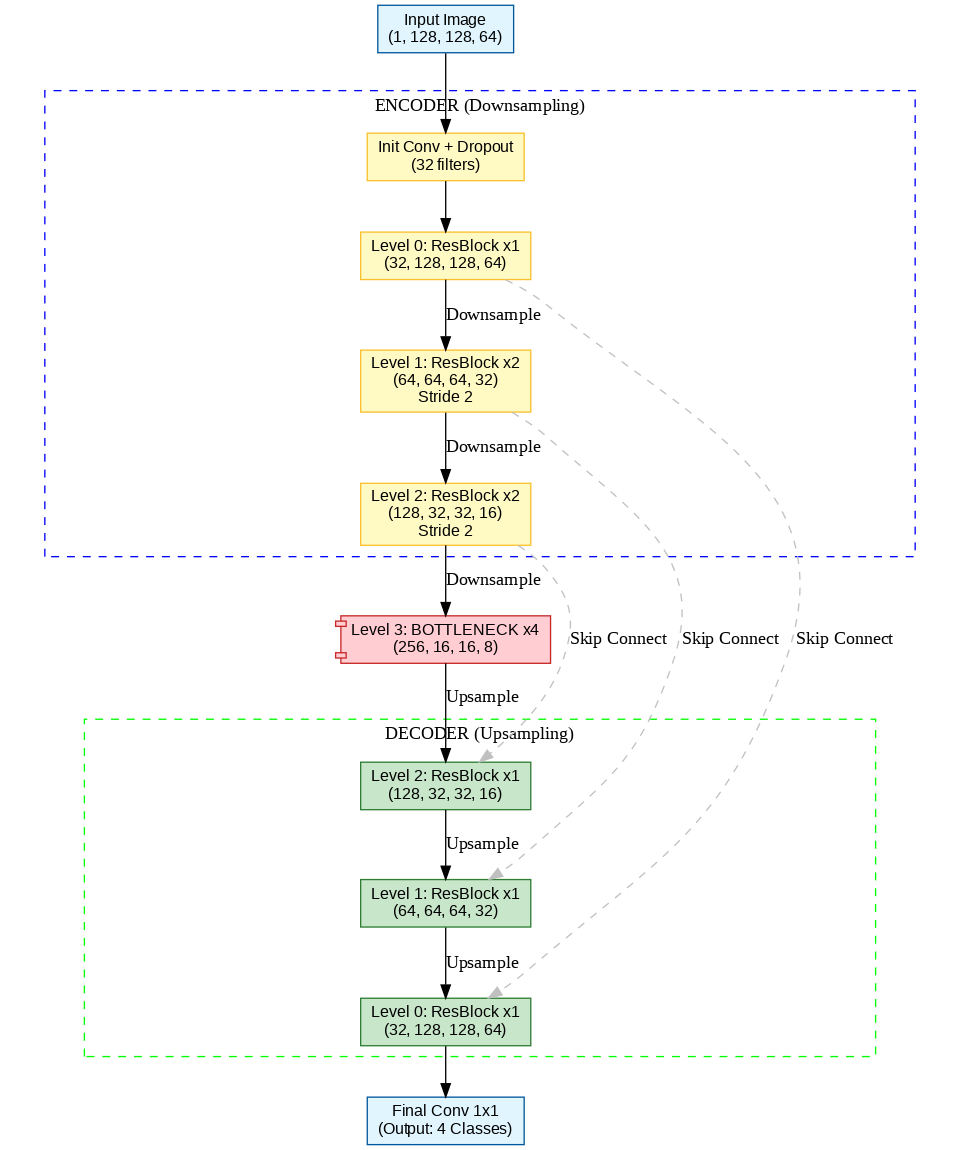

In [1]:
# Cài đặt thư viện (nếu chưa có)
# !pip install graphviz

import graphviz

def draw_segresnet_architecture():
    # Tạo đối tượng đồ thị
    dot = graphviz.Digraph('SegResNet', comment='Architecture', format='png')
    
    # Tùy chỉnh hiển thị (Đi từ trên xuống dưới, node hình chữ nhật)
    dot.attr(rankdir='TB', size='10,12', ratio='fill', compound='true')
    dot.attr('node', shape='box', style='filled', fontname='Arial', fontsize='12')
    
    # --- 1. INPUT ---
    dot.node('Input', 'Input Image\n(1, 128, 128, 64)', fillcolor='#E1F5FE', color='#01579B')
    
    # --- 2. ENCODER (Nhánh Xuống) ---
    with dot.subgraph(name='cluster_Encoder') as c:
        c.attr(label='ENCODER (Downsampling)', style='dashed', color='blue')
        c.attr('node', fillcolor='#FFF9C4', color='#FBC02D')
        
        c.node('Init', 'Init Conv + Dropout\n(32 filters)')
        c.node('Enc0', 'Level 0: ResBlock x1\n(32, 128, 128, 64)')
        c.node('Enc1', 'Level 1: ResBlock x2\n(64, 64, 64, 32)\nStride 2')
        c.node('Enc2', 'Level 2: ResBlock x2\n(128, 32, 32, 16)\nStride 2')
        
        c.edge('Init', 'Enc0')
        c.edge('Enc0', 'Enc1', label='Downsample')
        c.edge('Enc1', 'Enc2', label='Downsample')

    # --- 3. BOTTLENECK (Đáy) ---
    dot.node('Bot', 'Level 3: BOTTLENECK x4\n(256, 16, 16, 8)', fillcolor='#FFCDD2', color='#C62828', shape='component')
    
    # --- 4. DECODER (Nhánh Lên) ---
    with dot.subgraph(name='cluster_Decoder') as c:
        c.attr(label='DECODER (Upsampling)', style='dashed', color='green')
        c.attr('node', fillcolor='#C8E6C9', color='#2E7D32')
        
        c.node('Dec2', 'Level 2: ResBlock x1\n(128, 32, 32, 16)')
        c.node('Dec1', 'Level 1: ResBlock x1\n(64, 64, 64, 32)')
        c.node('Dec0', 'Level 0: ResBlock x1\n(32, 128, 128, 64)')
        
        c.edge('Dec2', 'Dec1', label='Upsample')
        c.edge('Dec1', 'Dec0', label='Upsample')

    # --- 5. OUTPUT ---
    dot.node('Final', 'Final Conv 1x1\n(Output: 4 Classes)', fillcolor='#E1F5FE', color='#01579B')
    
    # --- KẾT NỐI CHÍNH ---
    dot.edge('Input', 'Init')
    dot.edge('Enc2', 'Bot', label='Downsample')
    dot.edge('Bot', 'Dec2', label='Upsample')
    dot.edge('Dec0', 'Final')
    
    # --- SKIP CONNECTIONS (Đường nét đứt) ---
    # constraint=false giúp vẽ đường ngang mà không ảnh hưởng bố cục dọc
    dot.edge('Enc2', 'Dec2', label='Skip Connect', style='dashed', color='gray', constraint='false')
    dot.edge('Enc1', 'Dec1', label='Skip Connect', style='dashed', color='gray', constraint='false')
    dot.edge('Enc0', 'Dec0', label='Skip Connect', style='dashed', color='gray', constraint='false')

    # Render ra file
    try:
        output_path = dot.render('segresnet_architecture')
        print(f"✅ Đã vẽ xong! File ảnh được lưu tại: {output_path}")
        # Hiển thị ảnh trong notebook
        from IPython.display import Image
        display(Image(output_path))
    except Exception as e:
        print("⚠️ Lỗi render. Hãy đảm bảo bạn đã cài Graphviz trên máy/colab.")
        print("Lệnh cài đặt: !apt-get install graphviz (trên Colab/Linux) hoặc tải bộ cài Windows.")
        print(f"Chi tiết lỗi: {e}")

# Chạy hàm vẽ
draw_segresnet_architecture()